<div style="background:linear-gradient(135deg,#4F46E5 0%,#7C3AED 55%,#EC4899 100%);padding:28px 30px;border-radius:14px;color:white;font-family:Inter,Arial,sans-serif">
<h1 style="margin:0;color:white">🏠 Real Estate Investment Advisor</h1>
<h3 style="margin:6px 0 14px 0;color:#E0E7FF;font-weight:400">Predicting Property Profitability &amp; 5-Year Future Value across India — an end-to-end Data Analytics + ML project</h3>
<span style="background:rgba(255,255,255,.2);padding:4px 10px;border-radius:20px;margin-right:6px">Python</span>
<span style="background:rgba(255,255,255,.2);padding:4px 10px;border-radius:20px;margin-right:6px">Pandas</span>
<span style="background:rgba(255,255,255,.2);padding:4px 10px;border-radius:20px;margin-right:6px">Plotly</span>
<span style="background:rgba(255,255,255,.2);padding:4px 10px;border-radius:20px;margin-right:6px">Scikit-learn</span>
<span style="background:rgba(255,255,255,.2);padding:4px 10px;border-radius:20px;margin-right:6px">XGBoost</span>
<span style="background:rgba(255,255,255,.2);padding:4px 10px;border-radius:20px;margin-right:6px">MLflow</span>
<span style="background:rgba(255,255,255,.2);padding:4px 10px;border-radius:20px">Streamlit</span>
</div>

**Author:** P Suman Sangeet &nbsp;|&nbsp; **Domain:** Real Estate / Investment / Financial Analytics &nbsp;|&nbsp; **Stack:** Python · Pandas · Plotly · Scikit-learn · XGBoost · MLflow · Streamlit

### 🎯 Business problem
An investor looking at a listing needs two answers:

1. **Is this a *Good Investment*?** → binary **classification**
2. **What will this property be worth in 5 years?** → **regression** (`Future_Price_5Y`, in ₹ Lakhs)

### 🧭 Pipeline

<div style="display:flex;flex-wrap:wrap;gap:10px;font-family:Inter,Arial,sans-serif;font-size:14px;margin:10px 0">
<div style="background:#FEE2E2;border:2px solid #F87171;border-radius:10px;padding:10px 14px;color:#7F1D1D"><b>Step 1</b><br>Data Preprocessing<br>&amp; Feature Engineering</div>
<div style="align-self:center;font-size:22px">➜</div>
<div style="background:#FEF3C7;border:2px solid #FBBF24;border-radius:10px;padding:10px 14px;color:#78350F"><b>Step 2</b><br>Exploratory Data<br>Analysis (20 + 4 questions)</div>
<div style="align-self:center;font-size:22px">➜</div>
<div style="background:#DCFCE7;border:2px solid #4ADE80;border-radius:10px;padding:10px 14px;color:#14532D"><b>Step 3</b><br>Model Development<br>&amp; Evaluation</div>
<div style="align-self:center;font-size:22px">➜</div>
<div style="background:#DBEAFE;border:2px solid #60A5FA;border-radius:10px;padding:10px 14px;color:#1E3A8A"><b>Step 4</b><br>MLflow Tracking<br>&amp; Model Registry</div>
<div style="align-self:center;font-size:22px">➜</div>
<div style="background:#EDE9FE;border:2px solid #A78BFA;border-radius:10px;padding:10px 14px;color:#4C1D95"><b>Step 5</b><br>Streamlit App<br>(deployable)</div>
</div>

### 🗺️ Project roadmap (mirrors the project brief)

| Step | What happens | Output |
|---|---|---|
| **1. Data Preprocessing** | Quality audit, duplicates / missing values, outlier flags, feature engineering, target creation, encoding + scaling | Clean dataset + reusable `ColumnTransformer` |
| **2. Exploratory Data Analysis** | 20 brief questions + the 4 investment questions from the roadmap, all as interactive Plotly visuals | Insights per question |
| **3. Model Development** | Logistic Regression / Random Forest / XGBoost (classification) · Linear / Random Forest / XGBoost (regression) | Model comparison, ROC, confusion matrix, feature importance |
| **4. MLflow Integration** | Every run logs params, metrics, artifacts; best models go to the Model Registry | Experiment tracking + registered `champion` models |
| **5. Streamlit App** | Property form → *Good Investment?* + *Estimated price after 5 years* | `app.py` |

> 💡 **How to read this notebook:** every analysis cell ends with an **Insight** box whose numbers are *computed from the data*, so the narrative can never drift from the results.

### ⚠️ Read this first — four facts about the dataset that shape every decision
1. **The CSV has no target columns.** There is no `Good_Investment` label and no `Future_Price_5Y`; both are **engineered from documented domain rules**, so model scores measure how well the rules are learned — **not** real-market forecasting skill.
2. **`Crime rate`, `infrastructure score` and `RERA` from the brief are not in the data.** An Infrastructure Score is built from schools / hospitals / transport, and `Security` is the safety proxy.
3. **The data looks synthetic** (uniform distributions, price ⟂ size) — the notebook reports this openly instead of inventing stories.
4. **`Price_per_SqFt` in the CSV is ₹ Lakh/sq ft rounded to 2 decimals**, so it is recomputed in ₹/sq ft.

> 📂 **To run:** put `india_housing_prices.csv` next to this notebook → *Run All* (≈ 6–10 min). Dependencies are in `requirements.txt`.

## ⚙️ 0. Setup

In [1]:
import warnings, json, os, time, math
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from scipy import stats

import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 50, "display.float_format", "{:,.3f}".format)
RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)
REF_YEAR = 2025          # dataset reference year (Age_of_Property = 2025 - Year_Built)

# ---- consistent, recruiter-friendly visual theme -------------------------------------------
PALETTE = ["#2563EB", "#F59E0B", "#10B981", "#EF4444", "#8B5CF6", "#06B6D4", "#EC4899", "#64748B"]
pio.templates["re_theme"] = go.layout.Template(layout=dict(
    font=dict(family="Inter, Segoe UI, Arial", size=13, color="#1F2937"),
    colorway=PALETTE, plot_bgcolor="white", paper_bgcolor="white",
    title=dict(font=dict(size=18), x=0.01, xanchor="left"),
    xaxis=dict(showgrid=True, gridcolor="#EEF2F7", zeroline=False, linecolor="#CBD5E1"),
    yaxis=dict(showgrid=True, gridcolor="#EEF2F7", zeroline=False, linecolor="#CBD5E1"),
    legend=dict(bgcolor="rgba(255,255,255,0.7)"), margin=dict(l=60, r=30, t=70, b=55),
    hoverlabel=dict(font_size=12)))
pio.templates.default = "plotly_white+re_theme"
px.defaults.template = "plotly_white+re_theme"

def show(fig, title=None, h=470, **kw):
    """Apply a consistent finish and render."""
    if title: fig.update_layout(title_text=title)
    fig.update_layout(height=h, **kw)
    fig.show()

def insight(text):
    """Render a highlighted insight box (text is built from computed values)."""
    display(Markdown(f"> 💡 **Insight —** {text}"))

def strength(r):
    a = abs(r)
    return "negligible" if a < 0.05 else "weak" if a < 0.2 else "moderate" if a < 0.5 else "strong"

def lakh(x):   return f"₹{x:,.1f} L"
def inr(x):    return f"₹{x:,.0f}"
SAMPLE_N = 20_000        # interactive scatter/box plots use a sample to keep the notebook light
print("Setup complete ✔")

Setup complete ✔


## 📥 1. Load the data

In [2]:
CANDIDATES = ["india_housing_prices.csv", "data/india_housing_prices.csv",
              "/mnt/user-data/uploads/india_housing_prices.csv"]
DATA_PATH = next(p for p in CANDIDATES if os.path.exists(p))
raw = pd.read_csv(DATA_PATH)
print(f"Loaded {DATA_PATH}  →  {raw.shape[0]:,} rows × {raw.shape[1]} columns   |   memory: {raw.memory_usage(deep=True).sum()/1e6:,.1f} MB")
display(raw.head(5))

Loaded india_housing_prices.csv  →  250,000 rows × 23 columns   |   memory: 196.1 MB


,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,Furnished_Status,Floor_No,Total_Floors,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.760,0.100,1990,Furnished,22,1,35,10,3,High,No,No,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.520,0.080,2008,Unfurnished,21,20,17,8,1,Low,No,Yes,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.790,0.050,1997,Semi-furnished,19,27,28,9,8,Low,Yes,No,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.290,0.110,1991,Furnished,21,26,34,5,7,High,Yes,Yes,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.900,0.040,2002,Semi-furnished,3,2,23,4,9,Low,No,Yes,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move


In [3]:
overview = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "unique": raw.nunique(),
    "example": raw.iloc[0],
})
display(overview)

,dtype,missing,unique,example
ID,int64,0,250000,1
State,object,0,20,Tamil Nadu
City,object,0,42,Chennai
Locality,object,0,500,Locality_84
Property_Type,object,0,3,Apartment
BHK,int64,0,5,1
Size_in_SqFt,int64,0,4501,4740
Price_in_Lakhs,float64,0,48700,489.760
Price_per_SqFt,float64,0,100,0.100
Year_Built,int64,0,34,1990


---
<div style="background:#FEE2E2;border-left:8px solid #F87171;padding:12px 18px;border-radius:8px;color:#7F1D1D"><h2 style="margin:0">🧹 Step 1 — Data Preprocessing &amp; Feature Engineering</h2></div>

**Plan:** audit → deduplicate / impute → fix inconsistencies → recompute price-per-sqft → flag outliers → engineer features → build the two targets.

### 1.1 Data-quality audit
Before touching anything I check **completeness, uniqueness and logical consistency** — not just nulls.

In [4]:
df = raw.copy()

audit = {}
audit["Missing cells (total)"]               = int(df.isna().sum().sum())
audit["Duplicate rows (all columns)"]        = int(df.duplicated().sum())
audit["Duplicate rows (ignoring ID)"]        = int(df.drop(columns="ID").duplicated().sum())
audit["Duplicate IDs"]                       = int(df["ID"].duplicated().sum())
audit["Floor_No > Total_Floors (illogical)"] = int((df["Floor_No"] > df["Total_Floors"]).sum())
audit["Age ≠ 2025 − Year_Built"]             = int((df["Age_of_Property"] != REF_YEAR - df["Year_Built"]).sum())
audit["Price/SqFt column has ≤2 decimals (precision loss)"] = int((df["Price_per_SqFt"].round(2) == df["Price_per_SqFt"]).sum())
audit["Size ≤ 0 or Price ≤ 0"]               = int(((df["Size_in_SqFt"] <= 0) | (df["Price_in_Lakhs"] <= 0)).sum())
audit["1-BHK homes larger than 3,000 sqft (suspicious)"] = int(((df["BHK"] == 1) & (df["Size_in_SqFt"] > 3000)).sum())

audit_df = pd.DataFrame({"Check": audit.keys(), "Rows affected": audit.values()})
audit_df["% of data"] = (audit_df["Rows affected"] / len(df) * 100).round(2)
audit_df["Status"] = np.where(audit_df["Rows affected"] == 0, "✅ clean", "⚠️ needs action")
display(audit_df.style.hide(axis="index"))

Check,Rows affected,% of data,Status
Missing cells (total),0,0.000000,✅ clean
Duplicate rows (all columns),0,0.000000,✅ clean
Duplicate rows (ignoring ID),0,0.000000,✅ clean
Duplicate IDs,0,0.000000,✅ clean
Floor_No > Total_Floors (illogical),116304,46.520000,⚠️ needs action
Age ≠ 2025 − Year_Built,0,0.000000,✅ clean
Price/SqFt column has ≤2 decimals (precision loss),250000,100.000000,⚠️ needs action
Size ≤ 0 or Price ≤ 0,0,0.000000,✅ clean
"1-BHK homes larger than 3,000 sqft (suspicious)",22346,8.940000,⚠️ needs action


### 1.2 Cleaning decisions
| Issue found | Decision | Why |
|---|---|---|
| Missing values / duplicates | Pipeline-ready median / mode imputation + `drop_duplicates` (no-ops here but **kept in the code so the pipeline is reusable on new data**) | Production data is rarely this clean |
| `Floor_No > Total_Floors` | Raise `Total_Floors` to at least `Floor_No` | A flat on floor 22 implies a ≥22-storey building; changing the floor would destroy information |
| `Price_per_SqFt` has only 2 decimals in **lakhs** (e.g. `0.10`) | **Recompute** in ₹ per sq ft from price & size | Rounding error up to ±5 % otherwise |
| Outliers in price/sq ft | **Flag, don't delete** (IQR fences) | Extreme values are valid (small flats in expensive cities); trees are robust and `log` is used for plotting |

In [5]:
# --- duplicates & missing values (kept generic for reuse) -----------------------------------
n0 = len(df)
df = df.drop_duplicates(subset=[c for c in df.columns if c != "ID"]).reset_index(drop=True)
num_cols_raw = df.select_dtypes("number").columns.drop("ID")
cat_cols_raw = df.select_dtypes(exclude="number").columns
df[num_cols_raw] = df[num_cols_raw].fillna(df[num_cols_raw].median())
for c in cat_cols_raw:
    df[c] = df[c].fillna(df[c].mode()[0])
print(f"Rows removed as duplicates: {n0 - len(df):,}   |   missing values after imputation: {int(df.isna().sum().sum())}")

# --- logical fix ----------------------------------------------------------------------------
bad_floor = (df["Floor_No"] > df["Total_Floors"])
df["Total_Floors"] = np.maximum(df["Total_Floors"], df["Floor_No"])
print(f"Fixed {bad_floor.sum():,} rows where Floor_No exceeded Total_Floors")

# --- recompute price per sq ft in rupees -----------------------------------------------------
df["Price_per_SqFt_INR"] = df["Price_in_Lakhs"] * 1e5 / df["Size_in_SqFt"]

# --- outlier flags (IQR rule) ----------------------------------------------------------------
def iqr_flags(s, k=1.5):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr), (q1 - k * iqr, q3 + k * iqr)

outlier_rows = []
for col in ["Price_per_SqFt_INR", "Size_in_SqFt", "Price_in_Lakhs"]:
    flag, (lo, hi) = iqr_flags(df[col])
    df[f"Outlier_{col}"] = flag.astype(int)
    outlier_rows.append([col, f"{lo:,.0f}", f"{hi:,.0f}", int(flag.sum()), round(flag.mean() * 100, 2)])
display(pd.DataFrame(outlier_rows, columns=["Column", "Lower fence", "Upper fence", "# outliers", "% of rows"]).style.hide(axis="index"))

Rows removed as duplicates: 0   |   missing values after imputation: 0
Fixed 116,304 rows where Floor_No exceeded Total_Floors


Column,Lower fence,Upper fence,# outliers,% of rows
Price_per_SqFt_INR,"-11,974","32,764",19723,7.890000
Size_in_SqFt,"-1,754","7,250",0,0.000000
Price_in_Lakhs,-234,743,0,0.000000


### 1.3 Feature engineering
New features are written to **`real_estate_features.py`** so the *exact same logic* is imported by the Streamlit app — this prevents train/serve skew.

| Feature | Definition |
|---|---|
| `Price_per_SqFt_INR` | Price (₹) ÷ size |
| `Infrastructure_Score` (0-100) | 40 % schools + 30 % hospitals + 30 % public-transport access |
| `School_Density_Score` | Schools nearby ÷ average schools in that city |
| `Amenity_Count` | Number of amenities (gym, pool, clubhouse, garden, playground) |
| `Floor_Ratio` | `Floor_No / Total_Floors` (0 = ground, 1 = top floor) |
| `Sqft_per_BHK` | Space efficiency |
| `City_Median_PPSF`, `Price_vs_City_Median` | Is this listing cheap or expensive *for its city*? |

In [6]:
%%writefile real_estate_features.py
"""Shared feature-engineering logic (used by the notebook AND the Streamlit app)."""
import numpy as np
import pandas as pd

TRANSPORT_MAP = {"Low": 0.33, "Medium": 0.66, "High": 1.0}
AMENITY_LIST = ["Gym", "Pool", "Clubhouse", "Garden", "Playground"]
HORIZON_YEARS = 5


def engineer_features(df: pd.DataFrame, ref: dict) -> pd.DataFrame:
    """Add engineered columns. `ref` holds reference stats (city medians etc.)."""
    d = df.copy()
    d["Price_per_SqFt_INR"] = d["Price_in_Lakhs"] * 1e5 / d["Size_in_SqFt"]
    d["Infrastructure_Score"] = 100 * (
        0.40 * d["Nearby_Schools"] / 10
        + 0.30 * d["Nearby_Hospitals"] / 10
        + 0.30 * d["Public_Transport_Accessibility"].map(TRANSPORT_MAP)
    )
    city_avg_schools = d["City"].map(ref["city_avg_schools"]).fillna(ref["global_avg_schools"])
    d["School_Density_Score"] = (d["Nearby_Schools"] / city_avg_schools).round(3)
    d["Amenity_Count"] = d["Amenities"].fillna("").apply(lambda s: sum(a in s for a in AMENITY_LIST))
    d["Floor_Ratio"] = (d["Floor_No"] / d["Total_Floors"].clip(lower=1)).clip(upper=1)
    d["Sqft_per_BHK"] = d["Size_in_SqFt"] / d["BHK"]
    d["City_Median_PPSF"] = d["City"].map(ref["city_median_ppsf"]).fillna(ref["global_median_ppsf"])
    d["Price_vs_City_Median"] = d["Price_per_SqFt_INR"] / d["City_Median_PPSF"]
    d["Log_PPSF"] = np.log1p(d["Price_per_SqFt_INR"])
    d["Parking_Space"] = d["Parking_Space"].astype(str)
    d["Security"] = d["Security"].astype(str)
    return d


def add_targets(d: pd.DataFrame, ref: dict) -> pd.DataFrame:
    """Create the two target variables from transparent, documented domain rules."""
    d = d.copy()
    tier = d["City"].map(ref["city_tier"]).fillna(0)
    type_adj = d["Property_Type"].map({"Villa": 0.005, "Independent House": 0.0025}).fillna(0.0)
    infra_adj = (d["Infrastructure_Score"] - 50) / 50 * 0.01
    build_adj = np.where(d["Availability_Status"] == "Under_Construction", 0.01, 0.0)
    age_adj = -(d["Age_of_Property"].clip(upper=35) / 35) * 0.01
    d["Annual_Growth_Rate"] = (0.06 + tier + type_adj + infra_adj + build_adj + age_adj).clip(0.04, 0.12)
    d["Future_Price_5Y"] = d["Price_in_Lakhs"] * (1 + d["Annual_Growth_Rate"]) ** HORIZON_YEARS
    score = (
        (d["Price_per_SqFt_INR"] <= d["City_Median_PPSF"]).astype(int)
        + (d["Annual_Growth_Rate"] >= ref["median_growth"]).astype(int)
        + (d["BHK"] >= 3).astype(int)
        + (d["Availability_Status"] == "Ready_to_Move").astype(int)
        + (d["Infrastructure_Score"] >= ref["median_infra"]).astype(int)
    )
    d["Investment_Score"] = score
    d["Good_Investment"] = (score >= 3).astype(int)
    return d

Overwriting real_estate_features.py


In [7]:
import importlib, real_estate_features as ref_feat
importlib.reload(ref_feat)
from real_estate_features import engineer_features, add_targets

# ---- reference statistics (computed once on the full cleaned data, saved for the app) --------
city_med_ppsf = df.groupby("City")["Price_per_SqFt_INR"].median()
city_rank = city_med_ppsf.rank(pct=True)
city_tier = pd.Series(np.select([city_rank > 2/3, city_rank > 1/3], [0.02, 0.01], 0.0), index=city_med_ppsf.index)

REF = dict(
    city_median_ppsf = city_med_ppsf.to_dict(),
    global_median_ppsf = float(df["Price_per_SqFt_INR"].median()),
    city_avg_schools = df.groupby("City")["Nearby_Schools"].mean().to_dict(),
    global_avg_schools = float(df["Nearby_Schools"].mean()),
    city_tier = city_tier.to_dict(),          # annual-growth premium by city price-tier
    median_growth = 0.0, median_infra = 0.0,  # filled in below
)
_tmp = add_targets(engineer_features(df, REF), REF)
REF["median_growth"] = float(_tmp["Annual_Growth_Rate"].median())
REF["median_infra"]  = float(_tmp["Infrastructure_Score"].median())

data = add_targets(engineer_features(df, REF), REF)
print(f"Feature-engineered dataset: {data.shape[0]:,} × {data.shape[1]} columns")
display(data[["City", "Property_Type", "BHK", "Price_in_Lakhs", "Price_per_SqFt_INR", "Infrastructure_Score",
              "School_Density_Score", "Amenity_Count", "Floor_Ratio", "Annual_Growth_Rate",
              "Future_Price_5Y", "Investment_Score", "Good_Investment"]].head(6))

Feature-engineered dataset: 250,000 × 39 columns


,City,Property_Type,BHK,Price_in_Lakhs,Price_per_SqFt_INR,Infrastructure_Score,School_Density_Score,Amenity_Count,Floor_Ratio,Annual_Growth_Rate,Future_Price_5Y,Investment_Score,Good_Investment
0,Chennai,Apartment,1,489.760,"10,332.489",79.000,1.844,5,1.000,0.076,705.734,3,1
1,Pune,Independent House,3,195.520,"8,270.728",44.900,1.437,5,1.000,0.087,296.200,3,1
2,Ludhiana,Apartment,2,183.790,"5,046.403",69.900,1.649,4,0.704,0.056,241.324,3,1
3,Jodhpur,Independent House,2,300.290,"10,955.491",71.000,0.906,5,0.808,0.067,415.273,2,0
4,Jaipur,Villa,4,182.900,"3,792.245",52.900,0.724,5,1.000,0.059,243.619,3,1
5,Durgapur,Apartment,4,135.280,"3,865.143",58.900,1.275,2,1.000,0.060,181.335,4,1


### 1.4 Target variables — how they are defined
The dataset has **no historical price series and no resale labels**, so both targets are built from **transparent domain rules** (the approach suggested in the brief). I flag this clearly because it matters for how results should be read.

**🔹 Regression target — `Future_Price_5Y`**
`Future = Price × (1 + r)^5`, where the annual growth rate `r` is *feature-based*:

> `r = 6 %` base **+ city price-tier premium (0–2 %)** + property-type premium (Villa +0.5 %, House +0.25 %) **± infrastructure adjustment (±1 %)** + under-construction uplift (+1 %) − age penalty (up to −1 %), clipped to **4 %–12 %**

**🔹 Classification target — `Good_Investment`** (multi-factor score, 1 point each, **good if ≥ 3 / 5**)

| # | Rule |
|---|---|
| 1 | Price/sq ft ≤ **city median** (good value) |
| 2 | Annual growth rate ≥ dataset median (good appreciation) |
| 3 | BHK ≥ 3 (family-size demand / resale liquidity) |
| 4 | Ready-to-move (no construction risk) |
| 5 | Infrastructure score ≥ dataset median |

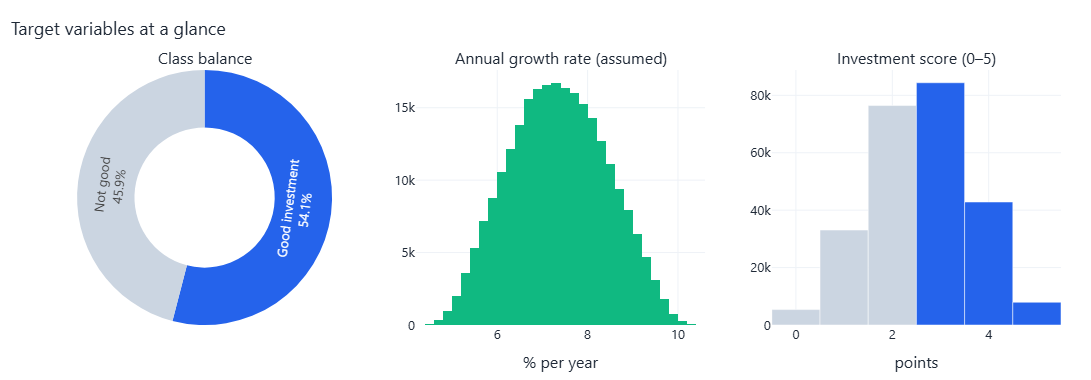

> 💡 **Insight —** **54.1%** of listings are labelled *Good Investment* — a near-balanced target, so accuracy is meaningful and no resampling is needed. Assumed annual growth ranges from **4.3%** to **10.4%** (median 7.3%), i.e. a typical 5-year price multiple of **1.43×**.

In [8]:
good_rate = data["Good_Investment"].mean()
fig = make_subplots(rows=1, cols=3, specs=[[{"type": "domain"}, {"type": "xy"}, {"type": "xy"}]],
                    subplot_titles=("Class balance", "Annual growth rate (assumed)", "Investment score (0–5)"))
vc = data["Good_Investment"].value_counts().sort_index()
fig.add_trace(go.Pie(labels=["Not good", "Good investment"], values=vc.values, hole=.55,
                     marker_colors=["#CBD5E1", "#2563EB"], textinfo="percent+label"), 1, 1)
fig.add_trace(go.Histogram(x=data["Annual_Growth_Rate"] * 100, nbinsx=40, marker_color="#10B981", name="growth %"), 1, 2)
sc = data["Investment_Score"].value_counts().sort_index()
fig.add_trace(go.Bar(x=sc.index, y=sc.values, marker_color=["#CBD5E1"] * 3 + ["#2563EB"] * 3, name="score"), 1, 3)
fig.update_xaxes(title_text="% per year", row=1, col=2); fig.update_xaxes(title_text="points", row=1, col=3)
fig.update_layout(showlegend=False)
show(fig, "Target variables at a glance", h=380)
insight(f"**{good_rate:.1%}** of listings are labelled *Good Investment* — a near-balanced target, so accuracy is meaningful and no resampling is needed. "
        f"Assumed annual growth ranges from **{data['Annual_Growth_Rate'].min():.1%}** to **{data['Annual_Growth_Rate'].max():.1%}** "
        f"(median {data['Annual_Growth_Rate'].median():.1%}), i.e. a typical 5-year price multiple of **{(1+data['Annual_Growth_Rate'].median())**5:.2f}×**.")

### 1.5 Encoding + scaling pipeline
One `ColumnTransformer` handles everything so **the same transformation is applied at train time and inside the app**:

* **Numeric** → `StandardScaler` (needed by Logistic / Linear Regression; harmless for trees)
* **Low-cardinality categoricals** (city, property type, furnishing, facing, …) → `OneHotEncoder`
* **High-cardinality `Locality` (500 values)** → `TargetEncoder` (cross-fitted internally, so it does **not leak** the target)

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder
from sklearn.pipeline import Pipeline

NUM_FEATURES = ["BHK", "Size_in_SqFt", "Price_in_Lakhs", "Price_per_SqFt_INR", "Log_PPSF", "Age_of_Property",
                "Floor_No", "Total_Floors", "Floor_Ratio", "Nearby_Schools", "Nearby_Hospitals",
                "School_Density_Score", "Infrastructure_Score", "Amenity_Count", "Sqft_per_BHK",
                "City_Median_PPSF", "Price_vs_City_Median"]
OHE_FEATURES = ["City", "Property_Type", "Furnished_Status", "Public_Transport_Accessibility", "Parking_Space",
                "Security", "Facing", "Owner_Type", "Availability_Status"]
TE_FEATURES = ["Locality"]
ALL_FEATURES = NUM_FEATURES + OHE_FEATURES + TE_FEATURES
PRICE_FEATURES = ["Price_in_Lakhs", "Price_per_SqFt_INR", "Log_PPSF", "Price_vs_City_Median", "City_Median_PPSF"]

def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), NUM_FEATURES),
        ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False), OHE_FEATURES),
        ("te",  TargetEncoder(random_state=RANDOM_STATE), TE_FEATURES),
    ])

# Never feed the targets (or anything computed from them) to the model
LEAKY = ["Annual_Growth_Rate", "Future_Price_5Y", "Investment_Score", "Good_Investment"]
assert not set(LEAKY) & set(ALL_FEATURES)
print(f"{len(NUM_FEATURES)} numeric + {len(OHE_FEATURES)} one-hot + {len(TE_FEATURES)} target-encoded input columns")
print("Excluded from model inputs (target-derived):", LEAKY)

17 numeric + 9 one-hot + 1 target-encoded input columns
Excluded from model inputs (target-derived): ['Annual_Growth_Rate', 'Future_Price_5Y', 'Investment_Score', 'Good_Investment']


In [10]:
os.makedirs("data", exist_ok=True); os.makedirs("models", exist_ok=True)
data.drop(columns=[c for c in data.columns if c.startswith("Outlier_")] + []).to_csv("data/cleaned_housing.csv", index=False)
data.sample(40_000, random_state=RANDOM_STATE).to_csv("data/app_sample.csv", index=False)   # light file for the Streamlit explorer
with open("models/reference.json", "w") as f: json.dump(REF, f)
print(f"💾 Saved: data/cleaned_housing.csv ({len(data):,} rows) · data/app_sample.csv (40,000 rows) · models/reference.json")

💾 Saved: data/cleaned_housing.csv (250,000 rows) · data/app_sample.csv (40,000 rows) · models/reference.json


---
<div style="background:#FEF3C7;border-left:8px solid #FBBF24;padding:12px 18px;border-radius:8px;color:#78350F"><h2 style="margin:0">🔍 Step 2 — Exploratory Data Analysis</h2></div>

All **20 questions from the project brief** are answered with interactive charts (hover, zoom, click legend items), followed by the four investment-specific analyses from the approach (area vs return, safety vs investment class, infrastructure vs resale value, price trends by city).

**20 business questions from the brief + the 4 investment questions from the roadmap.** All charts are **interactive** (hover for values, click legend items to isolate, drag to zoom).

> ⚠️ **Reading guide:** price per sq ft here is in **₹ per sq ft** (recomputed in Step 1). Large/dense plots use a random sample of 20,000 rows; every statistic and bar chart is computed on the **full 250,000 rows**.

In [11]:
samp = data.sample(SAMPLE_N, random_state=RANDOM_STATE)
PPSF, PRICE, SIZE = "Price_per_SqFt_INR", "Price_in_Lakhs", "Size_in_SqFt"

def hist_bar(series, bins=50, color="#2563EB", xtitle=""):
    counts, edges = np.histogram(series, bins=bins)
    ctr = (edges[:-1] + edges[1:]) / 2
    return go.Bar(x=ctr, y=counts, width=np.diff(edges) * 0.96, marker_color=color,
                  hovertemplate=xtitle + ": %{x:,.0f}<br>Listings: %{y:,}<extra></extra>")

def mean_ci_bar(col, value, order=None, title="", ytitle="", fmt=",.0f", colors=None):
    g = data.groupby(col)[value].agg(["mean", "std", "count"])
    g["ci"] = 1.96 * g["std"] / np.sqrt(g["count"])
    if order is not None: g = g.loc[order]
    fig = go.Figure(go.Bar(x=g.index.astype(str), y=g["mean"], error_y=dict(type="data", array=g["ci"], color="#334155"),
                           marker_color=colors or PALETTE[: len(g)], text=[f"{v:{fmt}}" for v in g["mean"]], textposition="outside",
                           hovertemplate="%{x}<br>Mean: %{y:,.2f}<extra></extra>"))
    fig.update_yaxes(title_text=ytitle, rangemode="tozero")
    return fig, g

def compare_groups(col, value):
    groups = [g[value].values for _, g in data.groupby(col)]
    if len(groups) == 2: _, p = stats.mannwhitneyu(*groups); test = "Mann-Whitney U"
    else: _, p = stats.kruskal(*groups); test = "Kruskal-Wallis"
    m = data.groupby(col)[value].mean()
    spread = (m.max() - m.min()) / m.mean() * 100
    return test, p, spread, m.idxmax(), m.idxmin()

def group_insight(col, value, label):
    test, p, spread, hi, lo = compare_groups(col, value)
    sig = "statistically significant" if p < 0.05 else "not statistically significant"
    size = "practically negligible" if spread < 2 else "small" if spread < 5 else "material"
    insight(f"Highest mean {label}: **{hi}**, lowest: **{lo}** — a gap of only **{spread:.1f}%** ({test} p = {p:.3g}, {sig}; effect is **{size}**).")

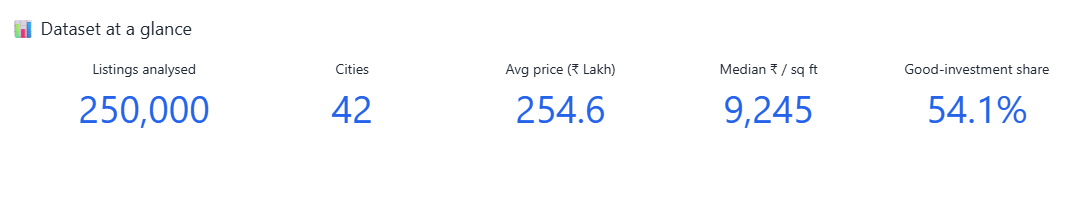

In [12]:
# 2.0  Executive snapshot — the dataset at a glance
kpis = [("Listings analysed", len(data), ",.0f", ""), ("Cities", data["City"].nunique(), ",.0f", ""),
        ("Avg price (₹ Lakh)", data[PRICE].mean(), ",.1f", ""), ("Median ₹ / sq ft", data[PPSF].median(), ",.0f", ""),
        ("Good-investment share", data["Good_Investment"].mean() * 100, ".1f", "%")]
fig = make_subplots(rows=1, cols=5, specs=[[{"type": "indicator"}] * 5])
for i, (t, v, f, suf) in enumerate(kpis, 1):
    fig.add_trace(go.Indicator(mode="number", value=v, title={"text": t, "font": {"size": 14}},
                               number={"valueformat": f, "suffix": suf, "font": {"color": PALETTE[0], "size": 38}}), 1, i)
show(fig, "📊 Dataset at a glance", h=200)

## 🅰️ 2A · Price & Size Analysis (Q1 – Q5)
### Q1 · What is the distribution of property prices?

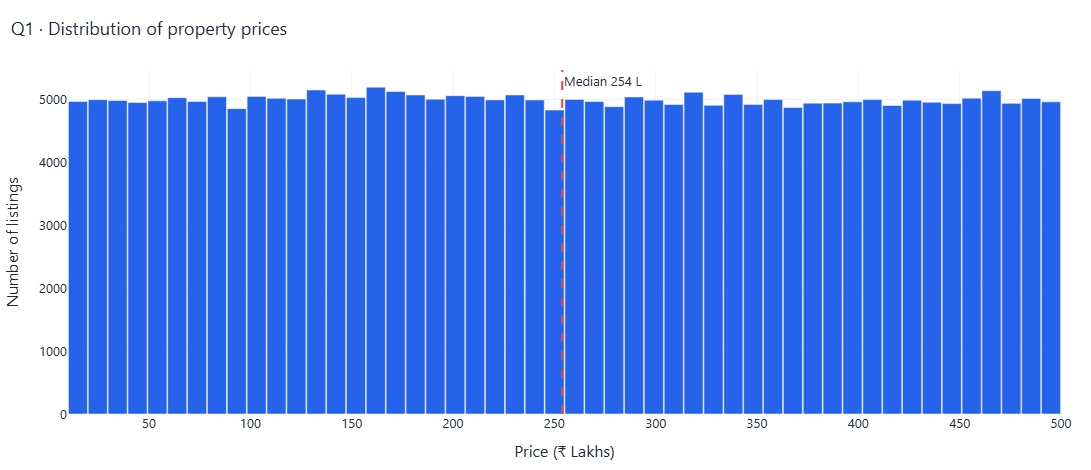

> 💡 **Insight —** Prices span **₹10.0 L – ₹500.0 L** with a median of **₹253.9 L** and mean of **₹254.6 L**. Skewness is **0.01** — the distribution is essentially **flat (uniform)** rather than the right-skewed shape typical of real housing markets.

In [13]:
fig = go.Figure(hist_bar(data[PRICE], 50, "#2563EB", "Price (₹ Lakhs)"))
fig.add_vline(x=data[PRICE].median(), line_dash="dash", line_color="#EF4444",
              annotation_text=f"Median {data[PRICE].median():,.0f} L", annotation_position="top right")
fig.update_xaxes(title_text="Price (₹ Lakhs)"); fig.update_yaxes(title_text="Number of listings")
show(fig, "Q1 · Distribution of property prices")
sk = stats.skew(data[PRICE])
insight(f"Prices span **{lakh(data[PRICE].min())} – {lakh(data[PRICE].max())}** with a median of **{lakh(data[PRICE].median())}** and mean of **{lakh(data[PRICE].mean())}**. "
        f"Skewness is **{sk:.2f}** — the distribution is essentially **flat (uniform)** rather than the right-skewed shape typical of real housing markets.")

### Q2 · What is the distribution of property sizes?

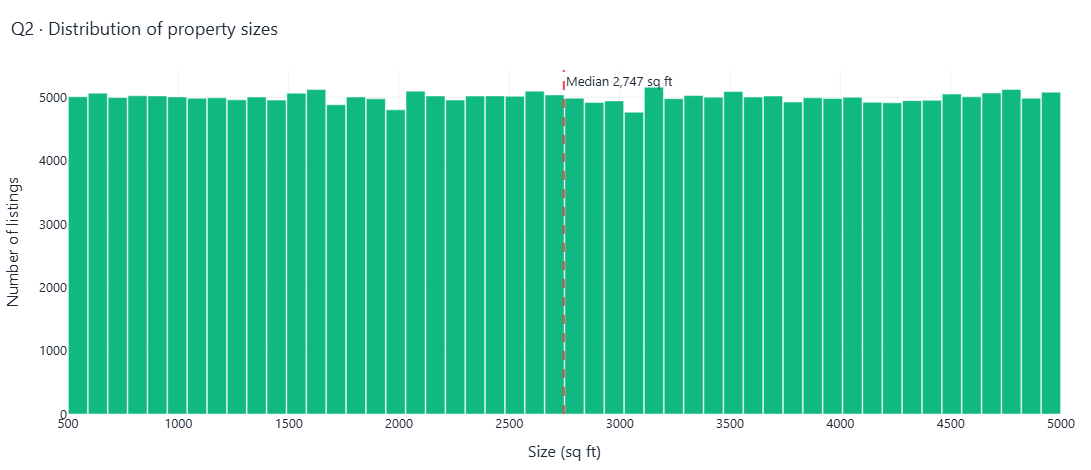

> 💡 **Insight —** Sizes range **500 – 5,000 sq ft** (median **2,747**, std **1,301**) — again a near-uniform spread, so every size band is well represented for modelling.

In [14]:
fig = go.Figure(hist_bar(data[SIZE], 50, "#10B981", "Size (sq ft)"))
fig.add_vline(x=data[SIZE].median(), line_dash="dash", line_color="#EF4444",
              annotation_text=f"Median {data[SIZE].median():,.0f} sq ft", annotation_position="top right")
fig.update_xaxes(title_text="Size (sq ft)"); fig.update_yaxes(title_text="Number of listings")
show(fig, "Q2 · Distribution of property sizes")
insight(f"Sizes range **{data[SIZE].min():,} – {data[SIZE].max():,} sq ft** (median **{data[SIZE].median():,.0f}**, std **{data[SIZE].std():,.0f}**) — again a near-uniform spread, so every size band is well represented for modelling.")

### Q3 · How does price per sq ft vary by property type?

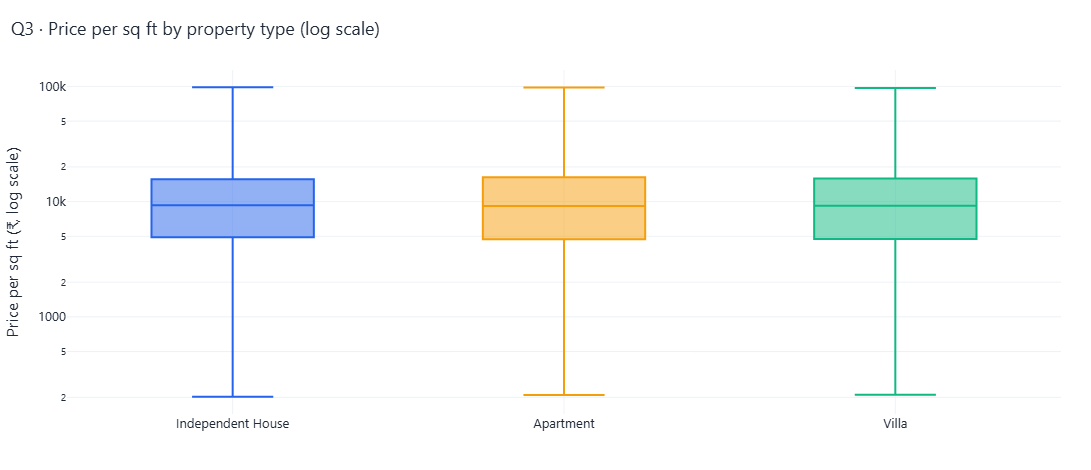

> 💡 **Insight —** Median price/sq ft — **Apartment: ₹9,245**, **Independent House: ₹9,305**, **Villa: ₹9,190**.

> 💡 **Insight —** Highest mean price/sq ft: **Independent House**, lowest: **Villa** — a gap of only **0.6%** (Kruskal-Wallis p = 0.0186, statistically significant; effect is **practically negligible**).

In [15]:
fig = px.box(samp, x="Property_Type", y=PPSF, color="Property_Type", log_y=True, points=False,
             labels={PPSF: "Price per sq ft (₹, log scale)", "Property_Type": ""})
fig.update_layout(showlegend=False)
show(fig, "Q3 · Price per sq ft by property type (log scale)")
med = data.groupby("Property_Type")[PPSF].median().round(0)
insight(f"Median price/sq ft — " + ", ".join(f"**{k}: {inr(v)}**" for k, v in med.items()) + ".")
group_insight("Property_Type", PPSF, "price/sq ft")

### Q4 · Is there a relationship between property size and price?

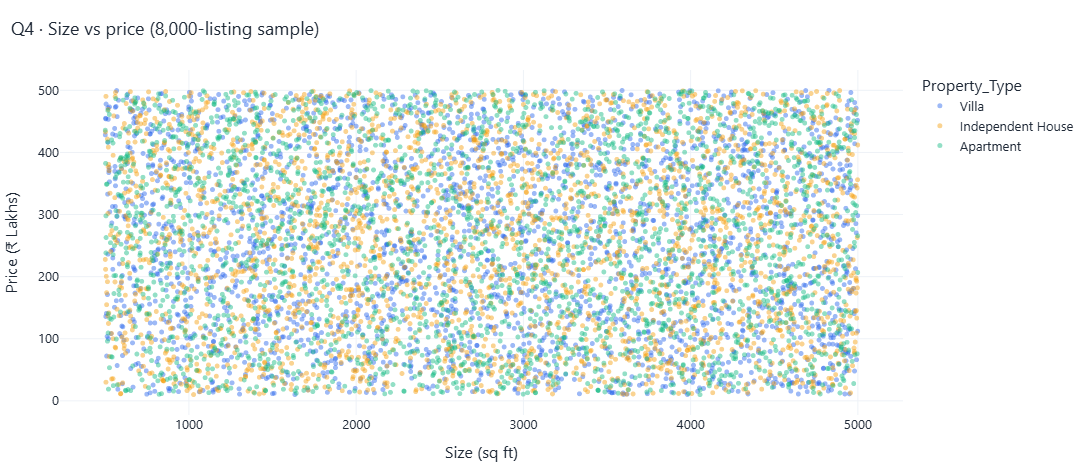

> 💡 **Insight —** The correlation between size and price is **negligible** (Pearson r = **-0.003**, Spearman ρ = -0.011). Because price does *not* rise with area, price **per sq ft** falls sharply as size grows (r = **-0.61**). In a real market I would expect r ≈ 0.7+, so this is a notable property of this dataset that I account for when interpreting later results.

In [16]:
fig = px.scatter(samp.sample(8000, random_state=1), x=SIZE, y=PRICE, color="Property_Type", opacity=.45,
                 labels={SIZE: "Size (sq ft)", PRICE: "Price (₹ Lakhs)"})
fig.update_traces(marker=dict(size=5))
show(fig, "Q4 · Size vs price (8,000-listing sample)")
r_sp, _ = stats.pearsonr(data[SIZE], data[PRICE]); r_sppsf, _ = stats.pearsonr(data[SIZE], data[PPSF])
rho, _ = stats.spearmanr(samp[SIZE], samp[PRICE])
insight(f"The correlation between size and price is **{strength(r_sp)}** (Pearson r = **{r_sp:+.3f}**, Spearman ρ = {rho:+.3f}). "
        f"Because price does *not* rise with area, price **per sq ft** falls sharply as size grows (r = **{r_sppsf:+.2f}**). "
        "In a real market I would expect r ≈ 0.7+, so this is a notable property of this dataset that I account for when interpreting later results.")

### Q5 · Are there outliers in price per sq ft or property size?

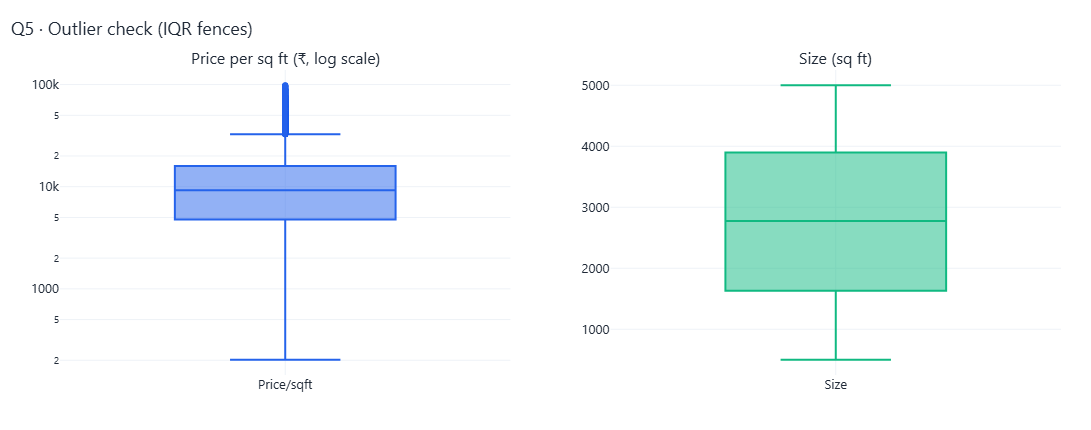

> 💡 **Insight —** **19,723 listings (7.9%)** are price/sq ft outliers (all on the *high* side — typically smaller flats at the top of the price range), while size has **0** outliers. They are plausible values, so they are **flagged but retained**; the `Log_PPSF` feature tames their influence.

In [17]:
fig = make_subplots(rows=1, cols=2, subplot_titles=("Price per sq ft (₹, log scale)", "Size (sq ft)"))
fig.add_trace(go.Box(y=samp[PPSF], name="Price/sqft", marker_color="#2563EB", boxpoints="outliers"), 1, 1)
fig.add_trace(go.Box(y=samp[SIZE], name="Size", marker_color="#10B981", boxpoints="outliers"), 1, 2)
fig.update_yaxes(type="log", row=1, col=1); fig.update_layout(showlegend=False)
show(fig, "Q5 · Outlier check (IQR fences)", h=430)
o1 = data["Outlier_Price_per_SqFt_INR"].sum(); o2 = data["Outlier_Size_in_SqFt"].sum()
_, (_lo, _hi) = iqr_flags(data[PPSF]); o1_high = int((data[PPSF] > _hi).sum())
insight(f"**{o1:,} listings ({o1/len(data):.1%})** are price/sq ft outliers ({"all" if o1_high == o1 else f"{o1_high:,}"} on the *high* side — typically smaller flats at the top of the price range), while size has **{o2:,}** outliers. "
        "They are plausible values, so they are **flagged but retained**; the `Log_PPSF` feature tames their influence.")

## 🅱️ 2B · Location-based Analysis (Q6 – Q10)
### Q6 · What is the average price per sq ft by state?

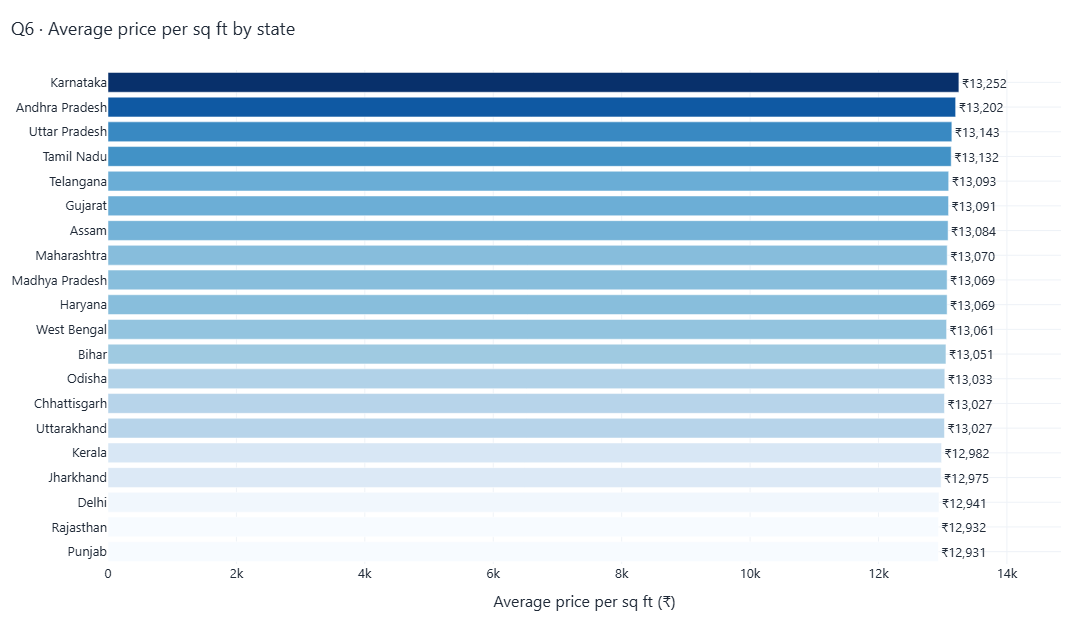

> 💡 **Insight —** **Karnataka** is the most expensive state per sq ft (**₹13,252**), **Punjab** the cheapest (**₹12,931**) — a spread of just **2.5%**, so state alone is not a strong price driver here.

In [18]:
s = data.groupby("State")[PPSF].mean().sort_values()
fig = go.Figure(go.Bar(y=s.index, x=s.values, orientation="h", marker=dict(color=s.values, colorscale="Blues"),
                       text=[f"₹{v:,.0f}" for v in s.values], textposition="outside"))
fig.update_xaxes(title_text="Average price per sq ft (₹)", range=[0, s.max() * 1.12])
show(fig, "Q6 · Average price per sq ft by state", h=620)
insight(f"**{s.idxmax()}** is the most expensive state per sq ft (**{inr(s.max())}**), **{s.idxmin()}** the cheapest (**{inr(s.min())}**) — a spread of just **{(s.max()-s.min())/s.mean():.1%}**, so state alone is not a strong price driver here.")

### Q7 · What is the average property price by city?

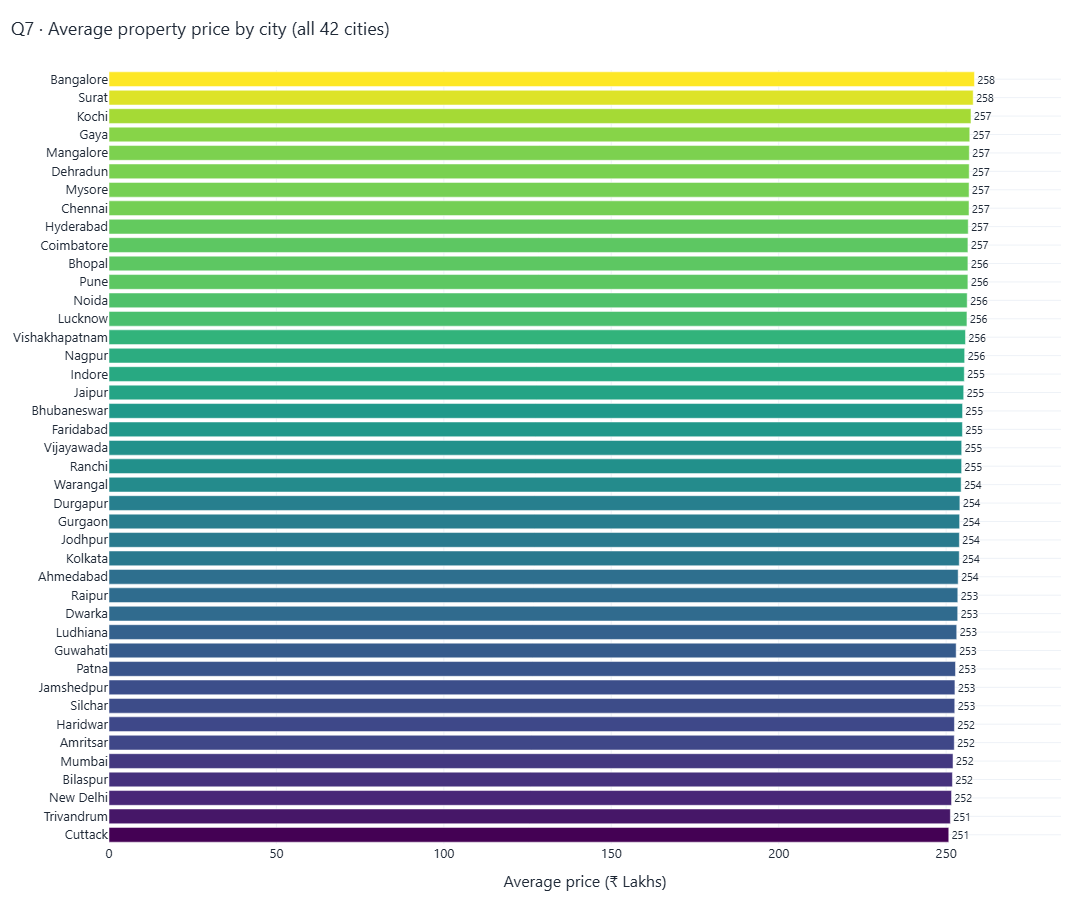

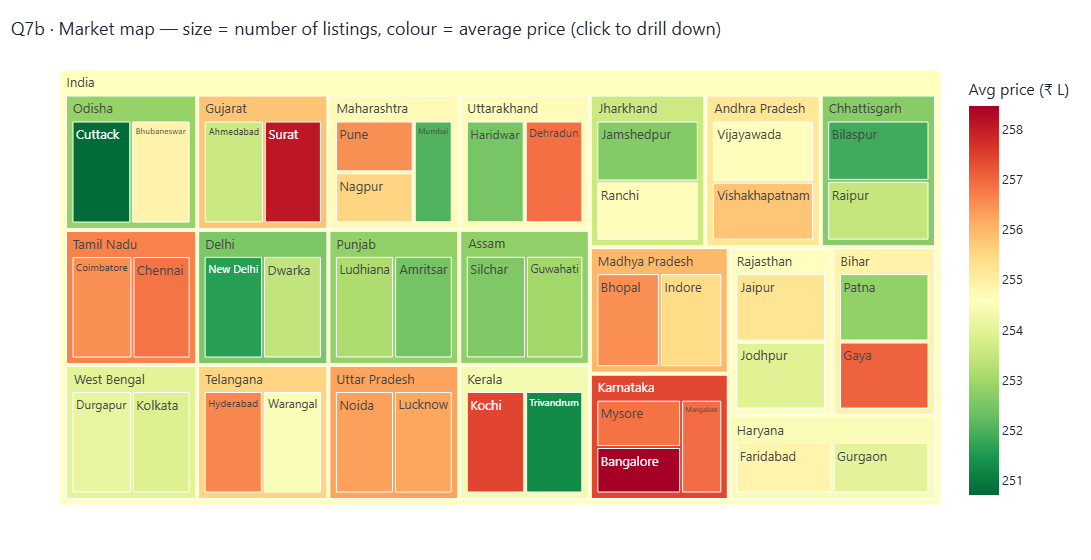

> 💡 **Insight —** Average city prices sit in a tight band — **Cuttack (₹250.8 L)** to **Bangalore (₹258.5 L)**, only **3.0%** apart. The treemap lets you drill from state to city to see where listing supply is concentrated.

In [19]:
c = data.groupby("City")[PRICE].mean().sort_values()
fig = go.Figure(go.Bar(y=c.index, x=c.values, orientation="h", marker=dict(color=c.values, colorscale="Viridis"),
                       text=[f"{v:,.0f}" for v in c.values], textposition="outside"))
fig.update_xaxes(title_text="Average price (₹ Lakhs)", range=[0, c.max() * 1.1])
show(fig, "Q7 · Average property price by city (all 42 cities)", h=900)

tm = data.groupby(["State", "City"]).agg(listings=("ID", "count"), avg_price=(PRICE, "mean")).reset_index()
fig = px.treemap(tm, path=[px.Constant("India"), "State", "City"], values="listings", color="avg_price",
                 color_continuous_scale="RdYlGn_r", color_continuous_midpoint=data[PRICE].mean(),
                 labels={"avg_price": "Avg price (₹ L)"})
show(fig, "Q7b · Market map — size = number of listings, colour = average price (click to drill down)", h=560)
insight(f"Average city prices sit in a tight band — **{c.idxmin()} ({lakh(c.min())})** to **{c.idxmax()} ({lakh(c.max())})**, only **{(c.max()-c.min())/c.mean():.1%}** apart. "
        "The treemap lets you drill from state to city to see where listing supply is concentrated.")

### Q8 · What is the median age of properties by locality?

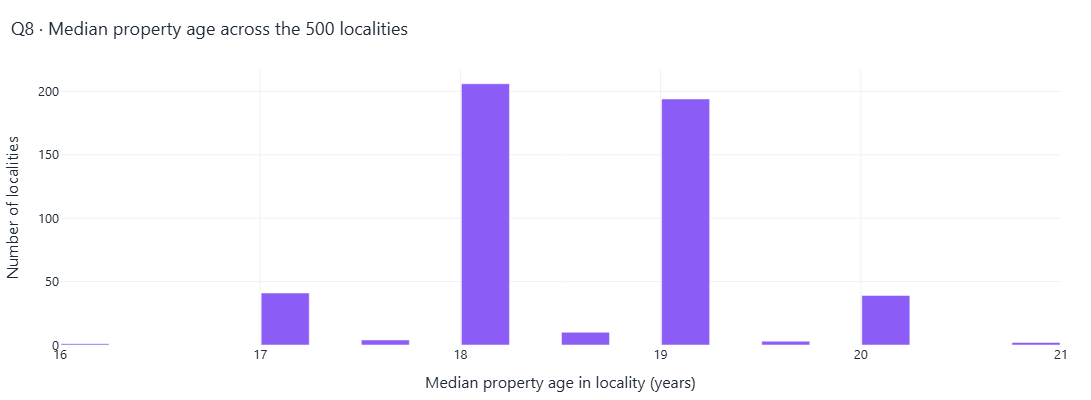

> 💡 **Insight —** Locality median age ranges **16–21 years** (overall median 18). Oldest stock: **Locality_72** (21 yrs), **Locality_403** (21 yrs), **Locality_75** (20 yrs), **Locality_127** (20 yrs), **Locality_1** (20 yrs). Newest: **Locality_443** (16 yrs), **Locality_92** (17 yrs), **Locality_60** (17 yrs), **Locality_10** (17 yrs), **Locality_13** (17 yrs).

In [20]:
loc_age = data.groupby("Locality")["Age_of_Property"].median()
fig = go.Figure(hist_bar(loc_age, 20, "#8B5CF6", "Median age (yrs)"))
fig.update_xaxes(title_text="Median property age in locality (years)"); fig.update_yaxes(title_text="Number of localities")
show(fig, "Q8 · Median property age across the 500 localities", h=400)
oldest = loc_age.sort_values(ascending=False).head(5); newest = loc_age.sort_values().head(5)
insight(f"Locality median age ranges **{loc_age.min():.0f}–{loc_age.max():.0f} years** (overall median {loc_age.median():.0f}). "
        f"Oldest stock: {', '.join(f'**{k}** ({v:.0f} yrs)' for k, v in oldest.items())}. Newest: {', '.join(f'**{k}** ({v:.0f} yrs)' for k, v in newest.items())}.")

### Q9 · How is BHK distributed across cities?

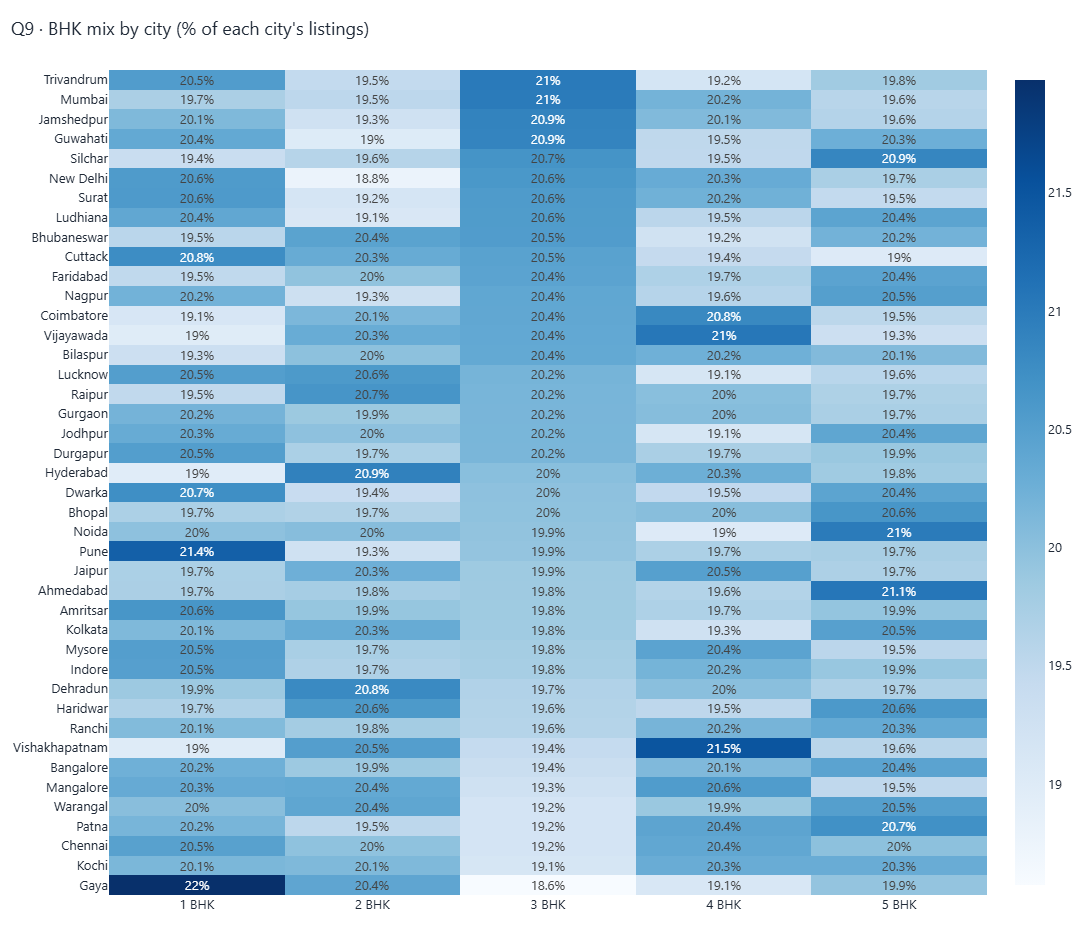

> 💡 **Insight —** Overall BHK mix — **1 BHK: 20.1%**, **2 BHK: 19.9%**, **3 BHK: 20.0%**, **4 BHK: 19.9%**, **5 BHK: 20.1%**. The mix is even in every city (largest city-level deviation from the national share: **1.9 pp**).

In [21]:
ct = pd.crosstab(data["City"], data["BHK"], normalize="index") * 100
ct = ct.sort_values(by=[3, 4, 5], ascending=False)
fig = go.Figure(go.Heatmap(z=ct.values, x=[f"{b} BHK" for b in ct.columns], y=ct.index, colorscale="Blues",
                           text=np.round(ct.values, 1), texttemplate="%{text}%", hovertemplate="%{y} · %{x}: %{z:.1f}%<extra></extra>"))
fig.update_yaxes(autorange="reversed")
show(fig, "Q9 · BHK mix by city (% of each city's listings)", h=950)
bhk_share = data["BHK"].value_counts(normalize=True).sort_index()
insight("Overall BHK mix — " + ", ".join(f"**{k} BHK: {v:.1%}**" for k, v in bhk_share.items()) +
        f". The mix is even in every city (largest city-level deviation from the national share: **{(ct - bhk_share.values*100).abs().max().max():.1f} pp**).")

### Q10 · What are the price trends for the top 5 most expensive localities?
*The dataset has no transaction dates, so the time axis is the **construction period** (`Year_Built`) — i.e. how pricing varies by property vintage.*

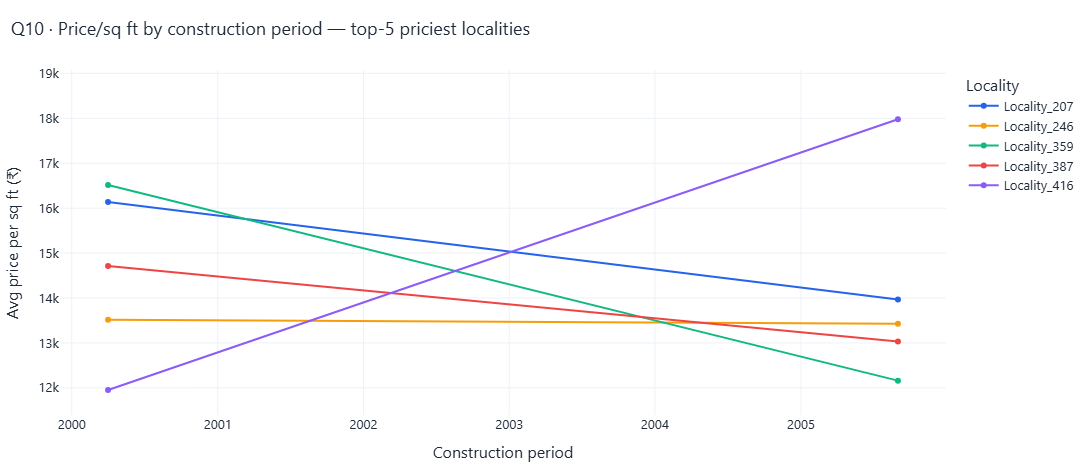

> 💡 **Insight —** Top-5 localities by average price/sq ft: **Locality_207** (₹15,204), **Locality_416** (₹14,765), **Locality_246** (₹14,567), **Locality_359** (₹14,485), **Locality_387** (₹14,430). Vintage shows **no consistent upward trend** — newer buildings are not systematically pricier, and the lines cross repeatedly.

In [22]:
top5 = data.groupby("Locality")[PPSF].mean().nlargest(5).index.tolist()
bins = [1989, 1994, 1999, 2004, 2009, 2014, 2019, 2023]
labels = ["1990-94", "1995-99", "2000-04", "2005-09", "2010-14", "2015-19", "2020-23"]
tmp = data[data["Locality"].isin(top5)].copy()
tmp["Build_Period"] = pd.cut(tmp["Year_Built"], bins=bins, labels=labels)
tr = tmp.groupby(["Locality", "Build_Period"], observed=True)[PPSF].mean().reset_index()
fig = px.line(tr, x="Build_Period", y=PPSF, color="Locality", markers=True,
              labels={PPSF: "Avg price per sq ft (₹)", "Build_Period": "Construction period"})
show(fig, "Q10 · Price/sq ft by construction period — top-5 priciest localities")
avg5 = data[data["Locality"].isin(top5)].groupby("Locality")[PPSF].mean().sort_values(ascending=False)
insight("Top-5 localities by average price/sq ft: " + ", ".join(f"**{k}** ({inr(v)})" for k, v in avg5.items()) +
        f". Vintage shows **no consistent upward trend** — newer buildings are not systematically pricier, and the lines cross repeatedly.")

## 🅲 2C · Feature Relationships & Correlation (Q11 – Q15)
### Q11 · How are numeric features correlated with each other?

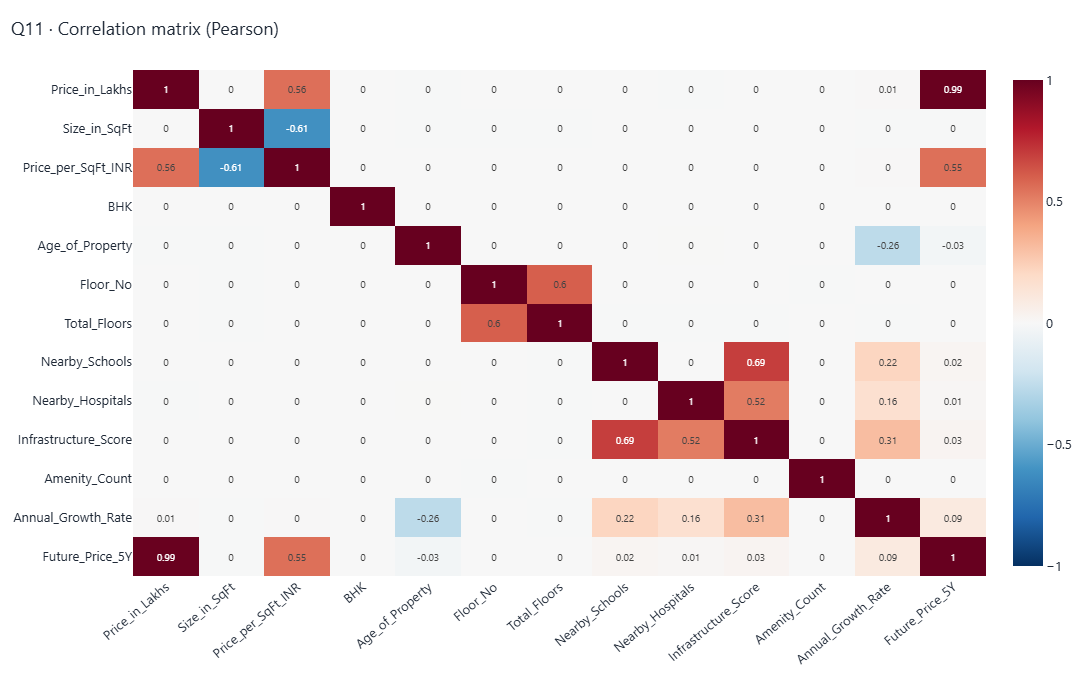

> 💡 **Insight —** Among the **raw** listing attributes the only notable link is **Floor_No ↔ Total_Floors** (r = +0.60) — and that one is partly *created by my Step-1 repair* (raising `Total_Floors` to at least `Floor_No`). Every other raw pair has |r| ≤ **0.004**, i.e. the attributes are statistically independent. The strong squares in the matrix come from **engineered** variables (price/sq ft = price ÷ size; `Future_Price_5Y` = price × growth) — not from independent market signals.

In [23]:
corr_cols = [PRICE, SIZE, PPSF, "BHK", "Age_of_Property", "Floor_No", "Total_Floors", "Nearby_Schools", "Nearby_Hospitals",
             "Infrastructure_Score", "Amenity_Count", "Annual_Growth_Rate", "Future_Price_5Y"]
cm = data[corr_cols].corr()
fig = go.Figure(go.Heatmap(z=cm.values, x=cm.columns, y=cm.index, zmin=-1, zmax=1, colorscale="RdBu", reversescale=True,
                           text=np.round(cm.values, 2), texttemplate="%{text}", textfont=dict(size=10)))
fig.update_yaxes(autorange="reversed"); fig.update_xaxes(tickangle=-40)
show(fig, "Q11 · Correlation matrix (Pearson)", h=680)
pairs = (cm.where(np.triu(np.ones(cm.shape), 1).astype(bool)).stack().rename("r").reset_index())
eng_cols = ["Annual_Growth_Rate", "Future_Price_5Y", "Infrastructure_Score", PPSF]
raw_pairs = pairs[~pairs["level_0"].isin(eng_cols) & ~pairs["level_1"].isin(eng_cols)]
raw_pairs = raw_pairs.reindex(raw_pairs["r"].abs().sort_values(ascending=False).index)
a0, b0, r0 = raw_pairs.iloc[0]; rest_max = raw_pairs["r"].iloc[1:].abs().max()
insight(f"Among the **raw** listing attributes the only notable link is **{a0} ↔ {b0}** (r = {r0:+.2f}) — and that one is partly *created by my Step-1 repair* "
        f"(raising `Total_Floors` to at least `Floor_No`). Every other raw pair has |r| ≤ **{rest_max:.3f}**, i.e. the attributes are statistically independent. "
        "The strong squares in the matrix come from **engineered** variables (price/sq ft = price ÷ size; `Future_Price_5Y` = price × growth) — not from independent market signals.")

### Q12 & Q13 · How do nearby schools / hospitals relate to price per sq ft?

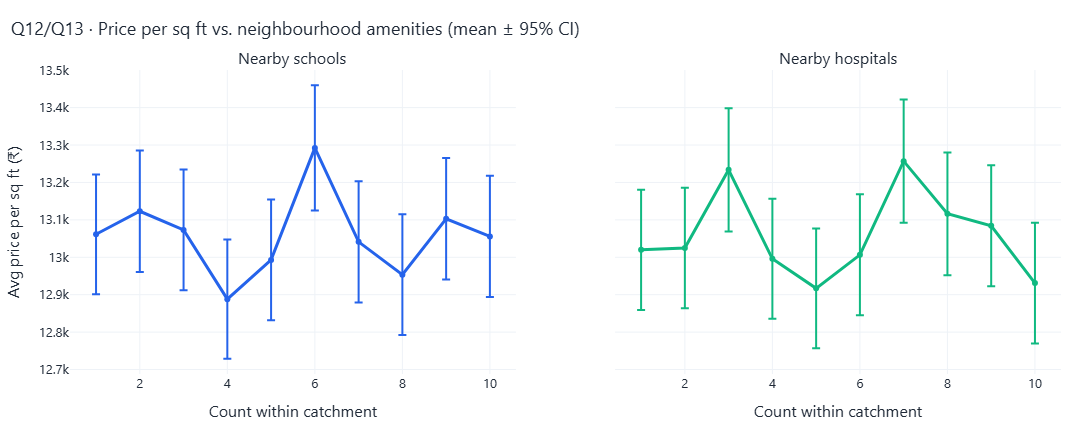

> 💡 **Insight —** Schools ↔ price/sq ft: r = **-0.000** (negligible); hospitals ↔ price/sq ft: r = **-0.000** (negligible). The confidence bands overlap across the whole range — proximity to schools or hospitals does **not** command a price premium in this data, which is why infrastructure is modelled as a *growth* driver (Step 1.4) rather than assumed to lift today's price.

In [24]:
fig = make_subplots(rows=1, cols=2, subplot_titles=("Nearby schools", "Nearby hospitals"), shared_yaxes=True)
for i, (col, color) in enumerate([("Nearby_Schools", "#2563EB"), ("Nearby_Hospitals", "#10B981")], start=1):
    g = data.groupby(col)[PPSF].agg(["mean", "std", "count"]); ci = 1.96 * g["std"] / np.sqrt(g["count"])
    fig.add_trace(go.Scatter(x=g.index, y=g["mean"], mode="lines+markers", line=dict(color=color, width=3),
                             error_y=dict(type="data", array=ci, visible=True), name=col), 1, i)
    fig.update_xaxes(title_text="Count within catchment", row=1, col=i)
fig.update_yaxes(title_text="Avg price per sq ft (₹)", row=1, col=1); fig.update_layout(showlegend=False)
show(fig, "Q12/Q13 · Price per sq ft vs. neighbourhood amenities (mean ± 95% CI)", h=430)
r_s, p_s = stats.pearsonr(data["Nearby_Schools"], data[PPSF]); r_h, p_h = stats.pearsonr(data["Nearby_Hospitals"], data[PPSF])
insight(f"Schools ↔ price/sq ft: r = **{r_s:+.3f}** ({strength(r_s)}); hospitals ↔ price/sq ft: r = **{r_h:+.3f}** ({strength(r_h)}). "
        "The confidence bands overlap across the whole range — proximity to schools or hospitals does **not** command a price premium in this data, "
        "which is why infrastructure is modelled as a *growth* driver (Step 1.4) rather than assumed to lift today's price.")

### Q14 · How does price vary by furnished status?

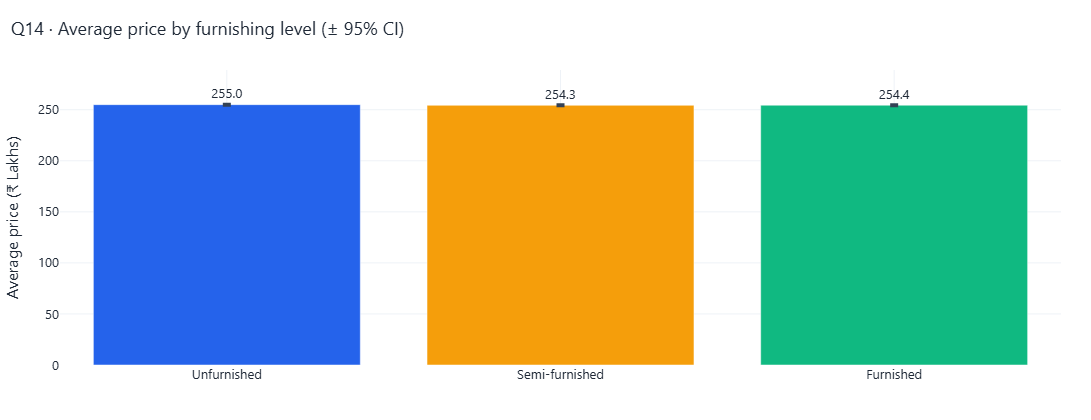

> 💡 **Insight —** Highest mean price: **Unfurnished**, lowest: **Semi-furnished** — a gap of only **0.3%** (Kruskal-Wallis p = 0.609, not statistically significant; effect is **practically negligible**).

In [25]:
fig, g = mean_ci_bar("Furnished_Status", PRICE, order=["Unfurnished", "Semi-furnished", "Furnished"],
                     ytitle="Average price (₹ Lakhs)", fmt=",.1f")
show(fig, "Q14 · Average price by furnishing level (± 95% CI)", h=420)
group_insight("Furnished_Status", PRICE, "price")

### Q15 · How does price per sq ft vary by property facing direction?

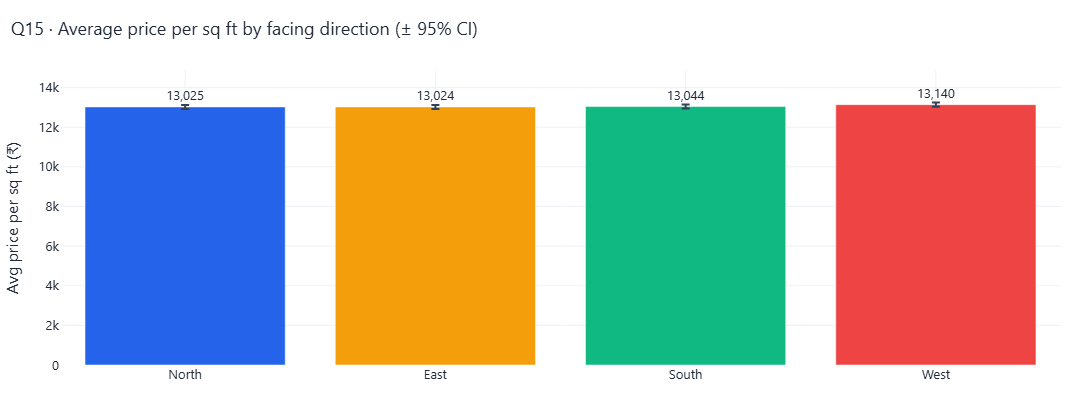

> 💡 **Insight —** Highest mean price/sq ft: **West**, lowest: **East** — a gap of only **0.9%** (Kruskal-Wallis p = 0.346, not statistically significant; effect is **practically negligible**).

In [26]:
fig, g = mean_ci_bar("Facing", PPSF, order=["North", "East", "South", "West"], ytitle="Avg price per sq ft (₹)")
show(fig, "Q15 · Average price per sq ft by facing direction (± 95% CI)", h=420)
group_insight("Facing", PPSF, "price/sq ft")

## 🅳 2D · Investment, Amenities & Ownership (Q16 – Q20)
### Q16 & Q17 · Properties by owner type and availability status

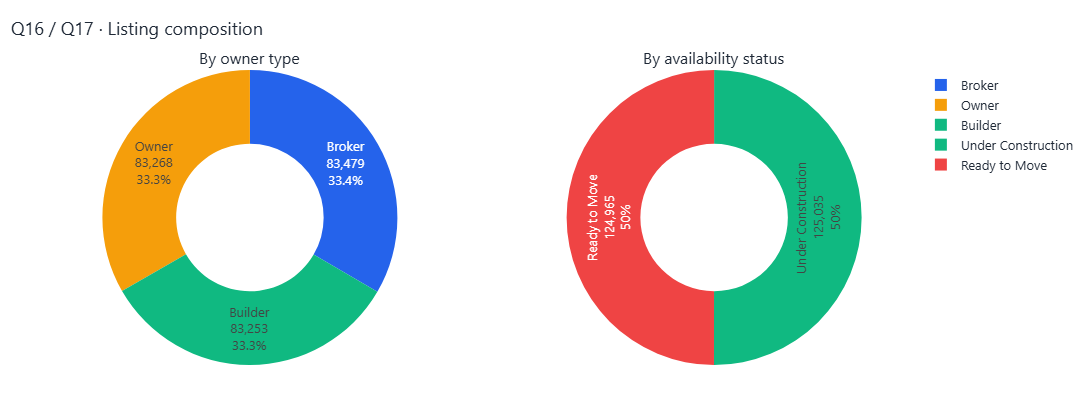

> 💡 **Insight —** Owner type — **Broker: 83,479 (33.4%)**, **Owner: 83,268 (33.3%)**, **Builder: 83,253 (33.3%)**. Availability — **Under Construction: 125,035 (50.0%)**, **Ready to Move: 124,965 (50.0%)**. Both splits are balanced, so no category is data-starved for modelling.

In [27]:
fig = make_subplots(rows=1, cols=2, specs=[[{"type": "domain"}, {"type": "domain"}]],
                    subplot_titles=("By owner type", "By availability status"))
ot = data["Owner_Type"].value_counts(); av = data["Availability_Status"].value_counts()
fig.add_trace(go.Pie(labels=ot.index, values=ot.values, hole=.5, marker_colors=PALETTE, textinfo="label+percent+value"), 1, 1)
fig.add_trace(go.Pie(labels=av.index.str.replace("_", " "), values=av.values, hole=.5, marker_colors=PALETTE[2:], textinfo="label+percent+value"), 1, 2)
show(fig, "Q16 / Q17 · Listing composition", h=420)
insight("Owner type — " + ", ".join(f"**{k}: {v:,} ({v/len(data):.1%})**" for k, v in ot.items()) +
        ". Availability — " + ", ".join(f"**{k.replace('_',' ')}: {v:,} ({v/len(data):.1%})**" for k, v in av.items()) +
        ". Both splits are balanced, so no category is data-starved for modelling.")

### Q18 · Does parking space affect property price?

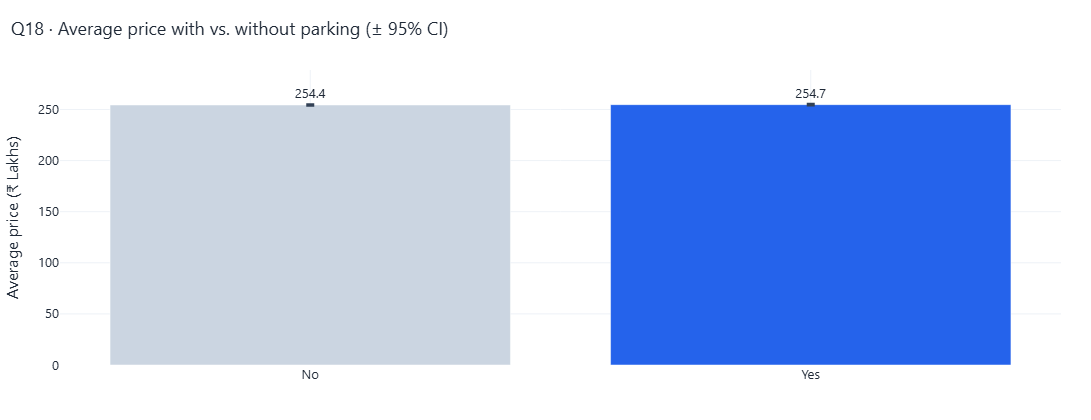

> 💡 **Insight —** Highest mean price: **Yes**, lowest: **No** — a gap of only **0.1%** (Mann-Whitney U p = 0.575, not statistically significant; effect is **practically negligible**).

> 💡 **Insight —** Listings **with** parking are priced **+0.12%** vs. those without (₹254.7 L vs ₹254.4 L).

In [28]:
fig, g = mean_ci_bar("Parking_Space", PRICE, order=["No", "Yes"], ytitle="Average price (₹ Lakhs)", fmt=",.1f", colors=["#CBD5E1", "#2563EB"])
show(fig, "Q18 · Average price with vs. without parking (± 95% CI)", h=420)
diff = (g.loc["Yes", "mean"] / g.loc["No", "mean"] - 1) * 100
group_insight("Parking_Space", PRICE, "price")
insight(f"Listings **with** parking are priced **{diff:+.2f}%** vs. those without ({lakh(g.loc['Yes','mean'])} vs {lakh(g.loc['No','mean'])}).")

### Q19 · How do amenities affect price per sq ft?

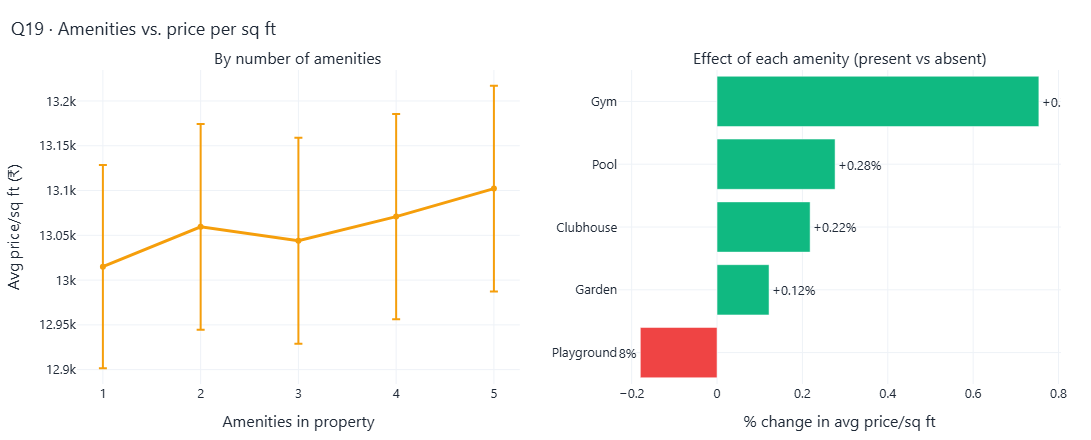

> 💡 **Insight —** Amenity count ↔ price/sq ft: r = **+0.002** (negligible). The single biggest per-amenity effect is **Gym (+0.75%)** — within noise. Amenities should be marketed as lifestyle features, not priced as a premium, on this evidence.

In [29]:
from real_estate_features import AMENITY_LIST
fig = make_subplots(rows=1, cols=2, subplot_titles=("By number of amenities", "Effect of each amenity (present vs absent)"))
g = data.groupby("Amenity_Count")[PPSF].agg(["mean", "std", "count"]); ci = 1.96 * g["std"] / np.sqrt(g["count"])
fig.add_trace(go.Scatter(x=g.index, y=g["mean"], mode="lines+markers", error_y=dict(type="data", array=ci),
                         line=dict(color="#F59E0B", width=3)), 1, 1)
eff = {}
for a in AMENITY_LIST:
    has = data["Amenities"].str.contains(a, na=False)
    eff[a] = (data.loc[has, PPSF].mean() / data.loc[~has, PPSF].mean() - 1) * 100
eff = pd.Series(eff).sort_values()
fig.add_trace(go.Bar(y=eff.index, x=eff.values, orientation="h", marker_color=["#EF4444" if v < 0 else "#10B981" for v in eff.values],
                     text=[f"{v:+.2f}%" for v in eff.values], textposition="outside"), 1, 2)
fig.update_xaxes(title_text="Amenities in property", row=1, col=1); fig.update_yaxes(title_text="Avg price/sq ft (₹)", row=1, col=1)
fig.update_xaxes(title_text="% change in avg price/sq ft", row=1, col=2); fig.update_layout(showlegend=False)
show(fig, "Q19 · Amenities vs. price per sq ft", h=440)
r_am, _ = stats.pearsonr(data["Amenity_Count"], data[PPSF])
insight(f"Amenity count ↔ price/sq ft: r = **{r_am:+.3f}** ({strength(r_am)}). The single biggest per-amenity effect is **{eff.abs().idxmax()} ({eff[eff.abs().idxmax()]:+.2f}%)** — "
        "within noise. Amenities should be marketed as lifestyle features, not priced as a premium, on this evidence.")

### Q20 · How does public-transport accessibility relate to price per sq ft *and* investment potential?

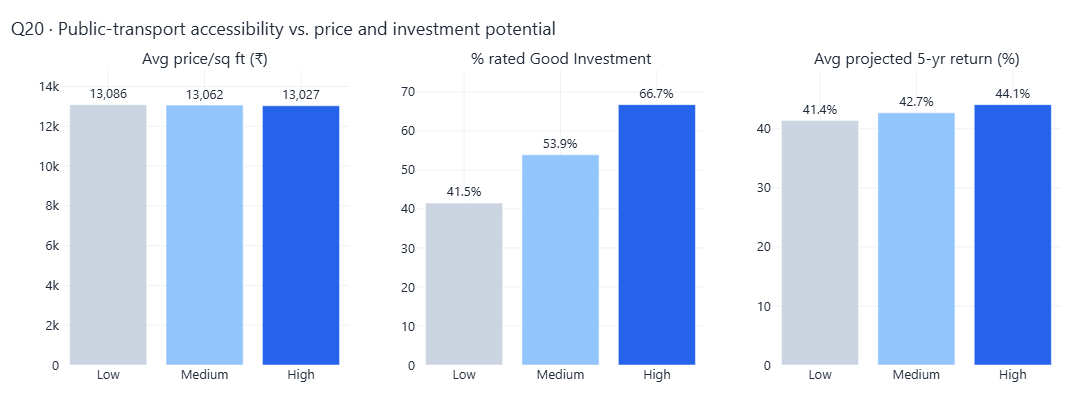

> 💡 **Insight —** Current price/sq ft differs by only **0.4%** across access levels (p = 0.611). But **investment potential rises with access**: Good-Investment rate goes **41.5% → 53.9% → 66.7%** and projected 5-yr return **41.4% → 44.1%** (transport is a component of the infrastructure score that drives growth). Good access is a *future-value* play, not a price premium today.

In [30]:
order = ["Low", "Medium", "High"]
g1 = data.groupby("Public_Transport_Accessibility")[PPSF].mean().loc[order]
g2 = data.groupby("Public_Transport_Accessibility")["Good_Investment"].mean().loc[order] * 100
g3 = ((data["Future_Price_5Y"] / data[PRICE] - 1) * 100).groupby(data["Public_Transport_Accessibility"]).mean().loc[order]
fig = make_subplots(rows=1, cols=3, subplot_titles=("Avg price/sq ft (₹)", "% rated Good Investment", "Avg projected 5-yr return (%)"))
for i, (s, fmt) in enumerate([(g1, "{:,.0f}"), (g2, "{:.1f}%"), (g3, "{:.1f}%")], start=1):
    fig.add_trace(go.Bar(x=order, y=s.values, marker_color=["#CBD5E1", "#93C5FD", "#2563EB"], text=[fmt.format(v) for v in s.values],
                         textposition="outside"), 1, i)
    fig.update_yaxes(rangemode="tozero", row=1, col=i)
fig.update_layout(showlegend=False)
show(fig, "Q20 · Public-transport accessibility vs. price and investment potential", h=420)
test, p, spread, hi, lo = compare_groups("Public_Transport_Accessibility", PPSF)
insight(f"Current price/sq ft differs by only **{spread:.1f}%** across access levels (p = {p:.3g}). But **investment potential rises with access**: "
        f"Good-Investment rate goes **{g2['Low']:.1f}% → {g2['Medium']:.1f}% → {g2['High']:.1f}%** and projected 5-yr return **{g3['Low']:.1f}% → {g3['High']:.1f}%** "
        "(transport is a component of the infrastructure score that drives growth). Good access is a *future-value* play, not a price premium today.")

## 🅴 2E · The four investment questions from the roadmap
### F1 · Price trends by city  *(use the dropdown to switch city)*

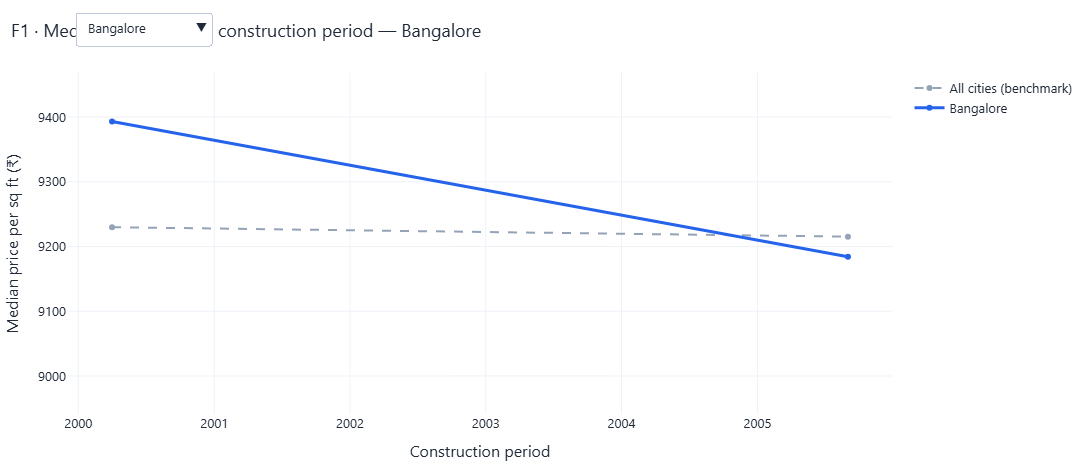

> 💡 **Insight —** Cities ranked by average price: **Bangalore, Surat, Kochi** lead; **New Delhi, Trivandrum, Cuttack** trail. Within a city, median price/sq ft moves by **9%** (median across cities) between vintages with no persistent direction — there is **no evidence of a time-based price trend** to extrapolate, which is why future value is modelled from property/location features.

In [31]:
data["Build_Period"] = pd.cut(data["Year_Built"], bins=bins, labels=labels)
trend_all = data.groupby("Build_Period", observed=True)[PPSF].median()
cities_sorted = data.groupby("City")[PRICE].mean().sort_values(ascending=False).index.tolist()
trend_city = data.groupby(["City", "Build_Period"], observed=True)[PPSF].median().unstack()

fig = go.Figure()
fig.add_trace(go.Scatter(x=labels, y=trend_all.values, name="All cities (benchmark)", mode="lines+markers",
                         line=dict(color="#94A3B8", dash="dash", width=2)))
for i, city in enumerate(cities_sorted):
    fig.add_trace(go.Scatter(x=labels, y=trend_city.loc[city].values, name=city, mode="lines+markers",
                             line=dict(color="#2563EB", width=3), visible=(i == 0)))
buttons = [dict(label=c, method="update",
                args=[{"visible": [True] + [j == i for j in range(len(cities_sorted))]}, {"title": f"F1 · Median price/sq ft by construction period — {c}"}])
          for i, c in enumerate(cities_sorted)]
fig.update_layout(updatemenus=[dict(buttons=buttons, direction="down", x=0.01, y=1.18, xanchor="left", showactive=True)])
fig.update_xaxes(title_text="Construction period"); fig.update_yaxes(title_text="Median price per sq ft (₹)")
show(fig, f"F1 · Median price/sq ft by construction period — {cities_sorted[0]}", h=470)
spreads = (trend_city.max(axis=1) - trend_city.min(axis=1)) / trend_city.mean(axis=1)
insight(f"Cities ranked by average price: **{', '.join(cities_sorted[:3])}** lead; **{', '.join(cities_sorted[-3:])}** trail. "
        f"Within a city, median price/sq ft moves by **{spreads.median():.0%}** (median across cities) between vintages with no persistent direction — "
        "there is **no evidence of a time-based price trend** to extrapolate, which is why future value is modelled from property/location features.")

### F2 · Correlation between area and investment return

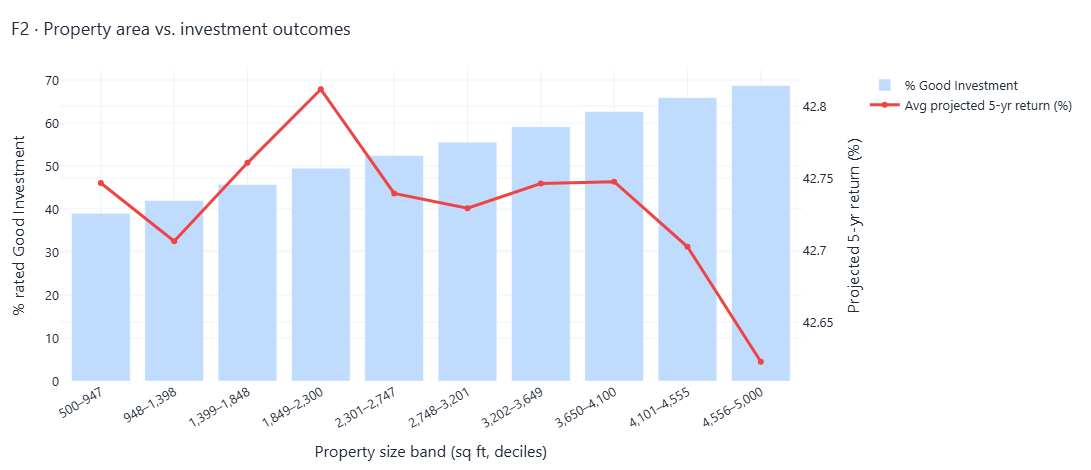

> 💡 **Insight —** Area ↔ projected return: r = **-0.003** (negligible) — bigger homes do not appreciate faster. Area ↔ *Good Investment* label: r = **+0.193** (weak); the Good rate climbs from **39%** (smallest decile) to **69%** (largest) because larger homes cost less per sq ft relative to their city median — a **value effect, not a growth effect**.

In [32]:
data["Return_5Y_pct"] = (data["Future_Price_5Y"] / data[PRICE] - 1) * 100
data["Size_Band"] = pd.qcut(data[SIZE], 10, labels=[f"D{i}" for i in range(1, 11)])
band_edges = data.groupby("Size_Band", observed=True)[SIZE].agg(["min", "max"])
gb = data.groupby("Size_Band", observed=True).agg(ret=("Return_5Y_pct", "mean"), good=("Good_Investment", "mean"))
xl = [f"{lo:,.0f}–{hi:,.0f}" for lo, hi in band_edges.values]
fig = make_subplots(specs=[[{"secondary_y": True}]])
fig.add_trace(go.Bar(x=xl, y=gb["good"] * 100, name="% Good Investment", marker_color="#BFDBFE"), secondary_y=False)
fig.add_trace(go.Scatter(x=xl, y=gb["ret"], name="Avg projected 5-yr return (%)", mode="lines+markers", line=dict(color="#EF4444", width=3)), secondary_y=True)
fig.update_xaxes(title_text="Property size band (sq ft, deciles)", tickangle=-30)
fig.update_yaxes(title_text="% rated Good Investment", secondary_y=False); fig.update_yaxes(title_text="Projected 5-yr return (%)", secondary_y=True)
show(fig, "F2 · Property area vs. investment outcomes", h=470)
r_ret, _ = stats.pearsonr(data[SIZE], data["Return_5Y_pct"]); r_good, _ = stats.pearsonr(data[SIZE], data["Good_Investment"])
insight(f"Area ↔ projected return: r = **{r_ret:+.3f}** ({strength(r_ret)}) — bigger homes do not appreciate faster. "
        f"Area ↔ *Good Investment* label: r = **{r_good:+.3f}** ({strength(r_good)}); the Good rate climbs from **{gb['good'].iloc[0]:.0%}** (smallest decile) to **{gb['good'].iloc[-1]:.0%}** (largest) "
        "because larger homes cost less per sq ft relative to their city median — a **value effect, not a growth effect**.")

### F3 · Impact of crime rate on Good-Investment classification
⚠️ **Crime rate is not part of this dataset.** I use the closest available safety/liveability proxies — the `Security` flag and the `Infrastructure_Score` — and say so explicitly rather than invent a crime column.m

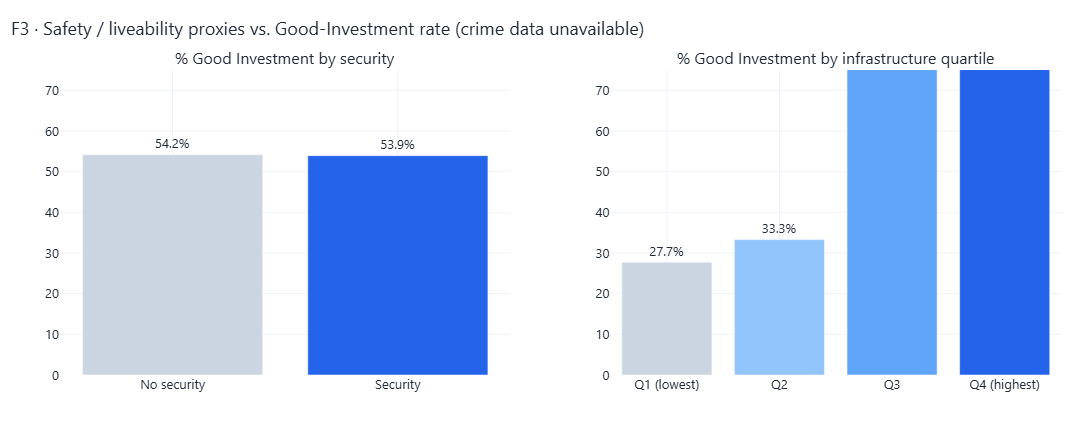

> 💡 **Insight —** Security has **no meaningful** effect on the label (54.2% → 53.9%; χ² p = 0.273), as expected — the label rules do not include it. Infrastructure, which *is* a label component, lifts the Good rate from **27.7%** (bottom quartile) to **80.2%** (top quartile). 💼 *Recommendation:* if a real crime-rate feed (e.g. NCRB district data) is merged by city/locality, it would slot into the infrastructure score without code changes.

In [33]:
fig = make_subplots(rows=1, cols=2, subplot_titles=("% Good Investment by security", "% Good Investment by infrastructure quartile"))
sec = data.groupby("Security")["Good_Investment"].mean() * 100
fig.add_trace(go.Bar(x=["No security", "Security"], y=sec.loc[["No", "Yes"]].values, marker_color=["#CBD5E1", "#2563EB"],
                     text=[f"{v:.1f}%" for v in sec.loc[["No", "Yes"]].values], textposition="outside"), 1, 1)
data["Infra_Quartile"] = pd.qcut(data["Infrastructure_Score"], 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
iq = data.groupby("Infra_Quartile", observed=True)["Good_Investment"].mean() * 100
fig.add_trace(go.Bar(x=iq.index.astype(str), y=iq.values, marker_color=["#CBD5E1", "#93C5FD", "#60A5FA", "#2563EB"],
                     text=[f"{v:.1f}%" for v in iq.values], textposition="outside"), 1, 2)
fig.update_yaxes(rangemode="tozero", range=[0, 75]); fig.update_layout(showlegend=False)
show(fig, "F3 · Safety / liveability proxies vs. Good-Investment rate (crime data unavailable)", h=430)
chi2, p_sec, _, _ = stats.chi2_contingency(pd.crosstab(data["Security"], data["Good_Investment"]))
insight(f"Security has **{'no meaningful' if abs(sec['Yes']-sec['No'])<1 else 'a measurable'}** effect on the label ({sec['No']:.1f}% → {sec['Yes']:.1f}%; χ² p = {p_sec:.3g}), as expected — the label rules do not include it. "
        f"Infrastructure, which *is* a label component, lifts the Good rate from **{iq.iloc[0]:.1f}%** (bottom quartile) to **{iq.iloc[-1]:.1f}%** (top quartile). "
        "💼 *Recommendation:* if a real crime-rate feed (e.g. NCRB district data) is merged by city/locality, it would slot into the infrastructure score without code changes.")

### F4 · Relationship between infrastructure score and resale value

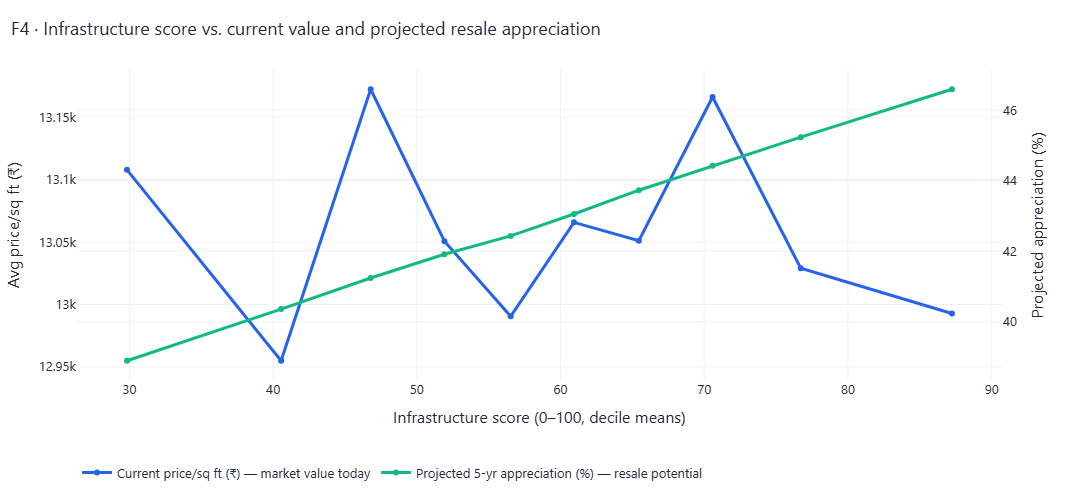

> 💡 **Insight —** Infrastructure ↔ **today's** price/sq ft: r = **-0.001** (negligible). Infrastructure ↔ **projected 5-year appreciation**: r = **+0.311** (moderate) — top-decile locations are projected to appreciate **46.6%** vs **38.9%** for the bottom decile. The second relationship is a **modelling assumption** (infrastructure drives growth), not an observed market fact.

In [34]:
data["Infra_Decile"] = pd.qcut(data["Infrastructure_Score"], 10, duplicates="drop")
gi = data.groupby("Infra_Decile", observed=True).agg(infra=("Infrastructure_Score", "mean"), ppsf=(PPSF, "mean"),
                                                   fut=("Future_Price_5Y", "mean"), now=(PRICE, "mean"))
fig = make_subplots(specs=[[{"secondary_y": True}]])
fig.add_trace(go.Scatter(x=gi["infra"], y=gi["ppsf"], name="Current price/sq ft (₹) — market value today", mode="lines+markers",
                         line=dict(color="#2563EB", width=3)), secondary_y=False)
fig.add_trace(go.Scatter(x=gi["infra"], y=(gi["fut"] / gi["now"] - 1) * 100, name="Projected 5-yr appreciation (%) — resale potential",
                         mode="lines+markers", line=dict(color="#10B981", width=3)), secondary_y=True)
fig.update_xaxes(title_text="Infrastructure score (0–100, decile means)")
fig.update_yaxes(title_text="Avg price/sq ft (₹)", secondary_y=False); fig.update_yaxes(title_text="Projected appreciation (%)", secondary_y=True)
fig.update_layout(legend=dict(orientation="h", y=-0.25))
show(fig, "F4 · Infrastructure score vs. current value and projected resale appreciation", h=500)
r_now, _ = stats.pearsonr(data["Infrastructure_Score"], data[PPSF]); r_fut, _ = stats.pearsonr(data["Infrastructure_Score"], data["Return_5Y_pct"])
insight(f"Infrastructure ↔ **today's** price/sq ft: r = **{r_now:+.3f}** ({strength(r_now)}). Infrastructure ↔ **projected 5-year appreciation**: r = **{r_fut:+.3f}** ({strength(r_fut)}) — "
        f"top-decile locations are projected to appreciate **{gi['fut'].iloc[-1]/gi['now'].iloc[-1]*100-100:.1f}%** vs **{gi['fut'].iloc[0]/gi['now'].iloc[0]*100-100:.1f}%** for the bottom decile. "
        "The second relationship is a **modelling assumption** (infrastructure drives growth), not an observed market fact.")

### 🎯 Investor view — where do the best opportunities sit?

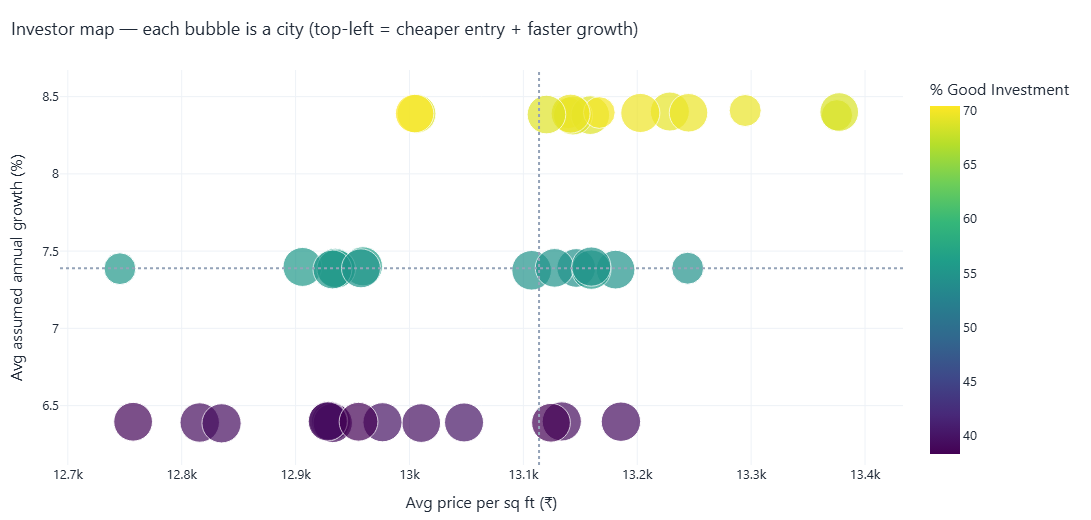

City,State,Listings,Avg ₹/sq ft,% Good Investment,Avg 5-yr return %
Guwahati,Assam,"6,092","₹13,004",70.4%,49.7%
Mumbai,Maharashtra,"4,149","₹13,167",69.9%,49.7%
Kochi,Kerala,"6,305","₹13,203",69.7%,49.7%
Bangalore,Karnataka,"4,144","₹13,140",69.6%,49.7%
Noida,Uttar Pradesh,"6,271","₹13,141",69.6%,49.7%
Vishakhapatnam,Andhra Pradesh,"6,118","₹13,245",69.5%,49.7%
Pune,Maharashtra,"4,224","₹13,295",69.4%,49.8%
Hyderabad,Telangana,"6,273","₹13,229",69.2%,49.8%
Ranchi,Jharkhand,"6,145","₹13,120",68.9%,49.6%
Chennai,Tamil Nadu,"6,168","₹13,159",68.9%,49.6%


> 💡 **Insight —** Top city by Good-Investment rate: **Guwahati** (70.4%). City-level rates run **38.3%–70.4%** — the growth premium for high-tier cities is partly offset by their higher entry price/sq ft, which is exactly the trade-off an investor must weigh.

In [35]:
city = data.groupby(["City", "State"]).agg(listings=("ID", "count"), ppsf=(PPSF, "mean"), growth=("Annual_Growth_Rate", "mean"),
                                            good=("Good_Investment", "mean"), ret=("Return_5Y_pct", "mean")).reset_index()
city["good_pct"] = city["good"] * 100; city["growth_pct"] = city["growth"] * 100
fig = px.scatter(city, x="ppsf", y="growth_pct", size="listings", color="good_pct", hover_name="City",
                 hover_data={"State": True, "ppsf": ":,.0f", "growth_pct": ":.2f", "good_pct": ":.1f", "listings": ":,"},
                 color_continuous_scale="Viridis", size_max=28,
                 labels={"ppsf": "Avg price per sq ft (₹)", "growth_pct": "Avg assumed annual growth (%)", "good_pct": "% Good Investment"})
fig.add_hline(y=city["growth_pct"].median(), line_dash="dot", line_color="#94A3B8")
fig.add_vline(x=city["ppsf"].median(), line_dash="dot", line_color="#94A3B8")
show(fig, "Investor map — each bubble is a city (top-left = cheaper entry + faster growth)", h=520)
top10 = city.sort_values(["good_pct", "ret"], ascending=False).head(10)[["City", "State", "listings", "ppsf", "good_pct", "ret"]]
top10.columns = ["City", "State", "Listings", "Avg ₹/sq ft", "% Good Investment", "Avg 5-yr return %"]
display(top10.style.hide(axis="index").format({"Listings": "{:,}", "Avg ₹/sq ft": "₹{:,.0f}", "% Good Investment": "{:.1f}%", "Avg 5-yr return %": "{:.1f}%"})
        .background_gradient(subset=["% Good Investment"], cmap="Blues"))
insight(f"Top city by Good-Investment rate: **{top10.iloc[0]['City']}** ({top10.iloc[0]['% Good Investment']:.1f}%). "
        f"City-level rates run **{city['good_pct'].min():.1f}%–{city['good_pct'].max():.1f}%** — the growth premium for high-tier cities is partly offset by their higher entry price/sq ft, which is exactly the trade-off an investor must weigh.")

# 🤖 STEP 3 & 4 — Model Development with MLflow Tracking
Two supervised tasks, each with **three models** of increasing complexity, all wrapped in the *same* preprocessing pipeline and **every run logged to MLflow**.

| Task | Target | Models | Metrics |
|---|---|---|---|
| **Classification** | `Good_Investment` | Logistic Regression · Random Forest · XGBoost | Accuracy · Precision · Recall · F1 · ROC-AUC |
| **Regression** | `Future_Price_5Y` (₹ L) | Linear Regression · Random Forest · XGBoost | RMSE · MAE · R² |

### 3.1 Train / test split
80 / 20, **stratified** on the classification label; the same rows are used for the regression task.

In [36]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from xgboost import XGBClassifier, XGBRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, mean_squared_error, mean_absolute_error, r2_score)

X = data[ALL_FEATURES]
y_clf = data["Good_Investment"]
y_reg = data["Future_Price_5Y"]
X_train, X_test, yc_train, yc_test, yr_train, yr_test = train_test_split(
    X, y_clf, y_reg, test_size=0.20, stratify=y_clf, random_state=RANDOM_STATE)
print(f"Train: {len(X_train):,} rows  |  Test: {len(X_test):,} rows  |  Positive rate train/test: {yc_train.mean():.3f} / {yc_test.mean():.3f}")

Train: 200,000 rows  |  Test: 50,000 rows  |  Positive rate train/test: 0.541 / 0.541


### 4.1 MLflow setup (Step 4 of the roadmap, wired in *before* training)
* **Tracking store:** local SQLite (`mlflow.db`) — launch the UI with `mlflow ui --backend-store-uri sqlite:///mlflow.db`
* **Two experiments:** `RealEstate_Classification` and `RealEstate_Regression`
* **Per run:** parameters, test metrics, training time, model artifact (full pipeline incl. preprocessing)

In [37]:
import mlflow, mlflow.sklearn, logging
logging.getLogger("mlflow").setLevel(logging.ERROR)   # keep the notebook output clean
from mlflow.models import infer_signature
mlflow.set_tracking_uri("sqlite:///mlflow.db")
EXP_CLF, EXP_REG = "RealEstate_Classification", "RealEstate_Regression"
CLF_REG_NAME, REG_REG_NAME = "RealEstate_GoodInvestment_Classifier", "RealEstate_FuturePrice_Regressor"

def clf_metrics(y_true, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    return dict(accuracy=accuracy_score(y_true, pred), precision=precision_score(y_true, pred), recall=recall_score(y_true, pred),
                f1=f1_score(y_true, pred), roc_auc=roc_auc_score(y_true, proba))

def reg_metrics(y_true, pred):
    return dict(rmse=float(np.sqrt(mean_squared_error(y_true, pred))), mae=mean_absolute_error(y_true, pred),
                r2=r2_score(y_true, pred), mape=float(np.mean(np.abs((y_true - pred) / y_true)) * 100))

def run_experiment(exp_name, run_name, pipe, Xtr, ytr, Xte, yte, task, params, tags=None):
    """Fit → evaluate → log everything to MLflow. Returns (fitted pipe, metrics, predictions)."""
    mlflow.set_experiment(exp_name)
    with mlflow.start_run(run_name=run_name):
        mlflow.log_params(params); mlflow.set_tags({"task": task, "dataset_rows": len(Xtr) + len(Xte), **(tags or {})})
        t0 = time.time(); pipe.fit(Xtr, ytr); fit_s = time.time() - t0
        if task == "classification":
            out = pipe.predict_proba(Xte)[:, 1]; m = clf_metrics(yte, out)
        else:
            out = pipe.predict(Xte); m = reg_metrics(yte, out)
        m["train_seconds"] = fit_s
        mlflow.log_metrics(m)
        sig = infer_signature(Xte.head(50), pipe.predict(Xte.head(50)))
        mlflow.sklearn.log_model(pipe, name="model", signature=sig, input_example=Xte.head(3),
                                 serialization_format="cloudpickle")
        run_id = mlflow.active_run().info.run_id
    m["run_id"] = run_id
    return pipe, m, out
print("MLflow tracking URI:", mlflow.get_tracking_uri())

MLflow tracking URI: sqlite:///mlflow.db


In [38]:

import mlflow
import mlflow.sklearn
import logging
import time
import numpy as np

from mlflow.models import infer_signature
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, mean_squared_error,
    mean_absolute_error, r2_score
)

logging.getLogger("mlflow").setLevel(logging.ERROR)

mlflow.set_tracking_uri("sqlite:///mlflow.db")

EXP_CLF = "RealEstate_Classification"
EXP_REG = "RealEstate_Regression"

CLF_REG_NAME = "RealEstate_GoodInvestment_Classifier"
REG_REG_NAME = "RealEstate_FuturePrice_Regressor"


def clf_metrics(y_true, proba, thr=0.5):
    pred = (proba >= thr).astype(int)

    return {
        "accuracy": float(accuracy_score(y_true, pred)),
        "precision": float(precision_score(y_true, pred, zero_division=0)),
        "recall": float(recall_score(y_true, pred, zero_division=0)),
        "f1": float(f1_score(y_true, pred, zero_division=0)),
        "roc_auc": float(roc_auc_score(y_true, proba))
    }


def reg_metrics(y_true, pred):
    y_true = np.asarray(y_true)
    pred = np.asarray(pred)

    nonzero = y_true != 0
    mape = (
        float(np.mean(np.abs(
            (y_true[nonzero] - pred[nonzero]) / y_true[nonzero]
        )) * 100)
        if np.any(nonzero) else float("nan")
    )

    return {
        "rmse": float(np.sqrt(mean_squared_error(y_true, pred))),
        "mae": float(mean_absolute_error(y_true, pred)),
        "r2": float(r2_score(y_true, pred)),
        "mape": mape
    }


def run_experiment(
    exp_name, run_name, pipe,
    Xtr, ytr, Xte, yte,
    task, params, tags=None
):
    """Fit, evaluate and log a model to MLflow."""

    mlflow.set_experiment(exp_name)

    with mlflow.start_run(run_name=run_name):

        mlflow.log_params(params)
        mlflow.set_tags({
            "task": task,
            "dataset_rows": str(len(Xtr) + len(Xte)),
            **(tags or {})
        })

        t0 = time.time()
        pipe.fit(Xtr, ytr)
        fit_s = time.time() - t0

        if task == "classification":
            out = pipe.predict_proba(Xte)[:, 1]
            metrics = clf_metrics(yte, out)
        else:
            out = pipe.predict(Xte)
            metrics = reg_metrics(yte, out)

        metrics["train_seconds"] = float(fit_s)

        # MLflow metrics must be numeric and finite.
        mlflow.log_metrics({
            key: float(value)
            for key, value in metrics.items()
            if np.isfinite(value)
        })

        # Match the model signature to the actual model output.
        example = Xte.head(3)
        signature_input = Xte.head(50)

        if task == "classification":
            signature_output = pipe.predict_proba(signature_input)
        else:
            signature_output = pipe.predict(signature_input)

        signature = infer_signature(
            signature_input,
            signature_output
        )

        # Older MLflow versions use artifact_path, not name.
        mlflow.sklearn.log_model(
            sk_model=pipe,
            artifact_path="model",
            signature=signature,
            input_example=example,
            serialization_format="cloudpickle"
        )

        run_id = mlflow.active_run().info.run_id

    metrics["run_id"] = run_id

    return pipe, metrics, out


print("MLflow version:", mlflow.__version__)
print("MLflow tracking URI:", mlflow.get_tracking_uri())


MLflow version: 3.15.2
MLflow tracking URI: sqlite:///mlflow.db


### 3.2 Classification — *Is this a Good Investment?*

In [39]:
def pipe_of(model): return Pipeline([("prep", make_preprocessor()), ("model", model)])

clf_specs = {
    "Logistic Regression": dict(model=LogisticRegression(max_iter=500, C=1.0), params=dict(model="LogisticRegression", C=1.0, max_iter=500)),
    "Random Forest":       dict(model=RandomForestClassifier(n_estimators=60, max_depth=12, min_samples_leaf=20, max_samples=0.35, n_jobs=-1, random_state=RANDOM_STATE),
                                params=dict(model="RandomForest", n_estimators=60, max_depth=12, min_samples_leaf=20, max_samples=0.35)),
    "XGBoost":             dict(model=XGBClassifier(n_estimators=250, max_depth=5, learning_rate=0.1, subsample=0.9, colsample_bytree=0.8,
                                                    tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE, eval_metric="logloss"),
                                params=dict(model="XGBoost", n_estimators=250, max_depth=5, learning_rate=0.1, subsample=0.9, colsample_bytree=0.8)),
}
clf_fitted, clf_results, clf_proba = {}, {}, {}
for name, spec in clf_specs.items():
    t = time.time()
    pipe, m, proba = run_experiment(EXP_CLF, name, pipe_of(spec["model"]), X_train, yc_train, X_test, yc_test, "classification",
                                    {**spec["params"], "n_features_in": len(ALL_FEATURES), "scaling": "StandardScaler", "encoding": "OHE+TargetEncoder"})
    clf_fitted[name], clf_results[name], clf_proba[name] = pipe, m, proba
    print(f"✔ {name:<20} AUC={m['roc_auc']:.4f}  Acc={m['accuracy']:.4f}  F1={m['f1']:.4f}   ({time.time()-t:.0f}s)")

✔ Logistic Regression  AUC=0.9376  Acc=0.8540  F1=0.8655   (20s)


✔ Random Forest        AUC=0.9967  Acc=0.9735  F1=0.9756   (15s)


✔ XGBoost              AUC=1.0000  Acc=0.9974  F1=0.9976   (34s)


,accuracy,precision,recall,f1,roc_auc,train_seconds
Logistic Regression,0.8540,0.8621,0.8689,0.8655,0.9376,4.0
Random Forest,0.9735,0.9716,0.9796,0.9756,0.9967,6.9
XGBoost,0.9974,0.9970,0.9982,0.9976,1.0000,14.4


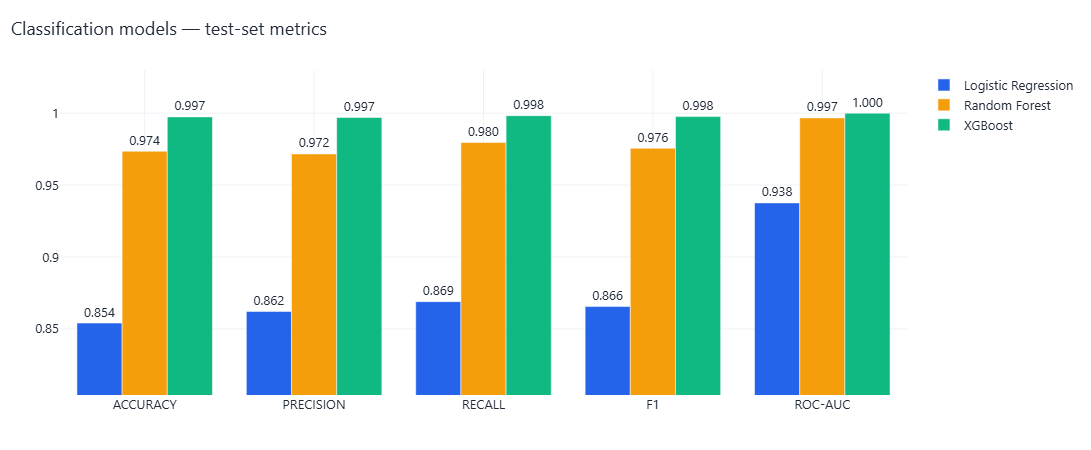

In [40]:
clf_df = pd.DataFrame(clf_results).T.drop(columns=["run_id"]).astype(float)
display(clf_df.style.format("{:.4f}", subset=["accuracy", "precision", "recall", "f1", "roc_auc"]).format("{:.1f}", subset=["train_seconds"])
        .highlight_max(subset=["accuracy", "precision", "recall", "f1", "roc_auc"], color="#BBF7D0"))

metrics_plot = ["accuracy", "precision", "recall", "f1", "roc_auc"]
fig = go.Figure()
for i, (name, row) in enumerate(clf_df.iterrows()):
    fig.add_trace(go.Bar(name=name, x=[m.upper().replace("_", "-") for m in metrics_plot], y=row[metrics_plot].values,
                         text=[f"{v:.3f}" for v in row[metrics_plot].values], textposition="outside", marker_color=PALETTE[i]))
fig.update_layout(barmode="group", yaxis=dict(range=[max(0, clf_df[metrics_plot].min().min() - 0.05), 1.03]))
show(fig, "Classification models — test-set metrics", h=450)

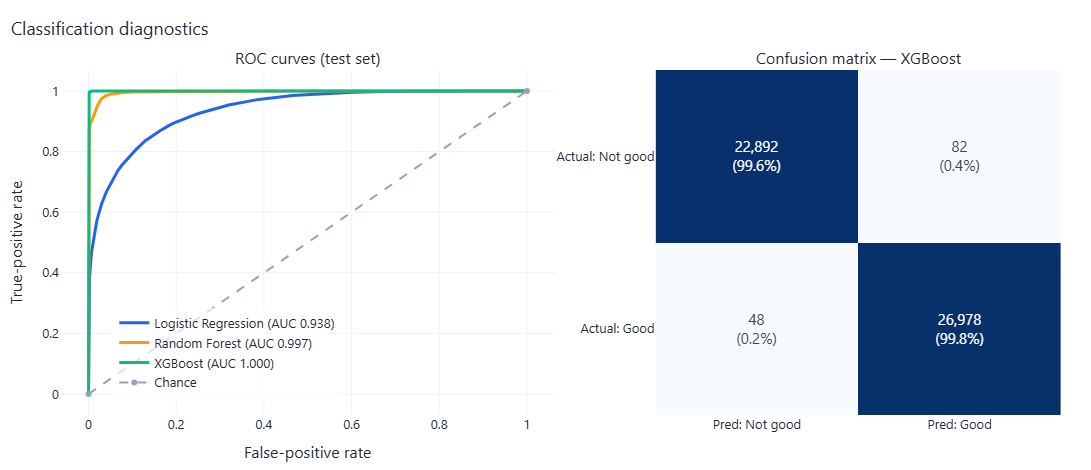

> 💡 **Insight —** **XGBoost** is the best classifier (ROC-AUC **1.0000**, accuracy **99.74%**, F1 **0.9976**). On 50,000 unseen listings it makes **130 errors** — 82 false alarms and 48 missed opportunities.

In [41]:
best_clf_name = clf_df["roc_auc"].idxmax(); best_clf = clf_fitted[best_clf_name]

# ---- ROC curves -------------------------------------------------------------------------------
fig = make_subplots(rows=1, cols=2, subplot_titles=("ROC curves (test set)", f"Confusion matrix — {best_clf_name}"), column_widths=[.55, .45])
for i, (name, proba) in enumerate(clf_proba.items()):
    fpr, tpr, _ = roc_curve(yc_test, proba)
    idx = np.linspace(0, len(fpr) - 1, min(400, len(fpr))).astype(int)
    fig.add_trace(go.Scatter(x=fpr[idx], y=tpr[idx], name=f"{name} (AUC {clf_results[name]['roc_auc']:.3f})", line=dict(color=PALETTE[i], width=3)), 1, 1)
fig.add_trace(go.Scatter(x=[0, 1], y=[0, 1], name="Chance", line=dict(color="#94A3B8", dash="dash")), 1, 1)
cm_ = confusion_matrix(yc_test, (clf_proba[best_clf_name] >= .5).astype(int))
cm_pct = cm_ / cm_.sum(axis=1, keepdims=True) * 100
fig.add_trace(go.Heatmap(z=cm_pct, x=["Pred: Not good", "Pred: Good"], y=["Actual: Not good", "Actual: Good"], colorscale="Blues", showscale=False,
                         text=[[f"{cm_[i][j]:,}<br>({cm_pct[i][j]:.1f}%)" for j in range(2)] for i in range(2)], texttemplate="%{text}",
                         textfont=dict(size=15)), 1, 2)
fig.update_yaxes(autorange="reversed", row=1, col=2)
fig.update_xaxes(title_text="False-positive rate", row=1, col=1); fig.update_yaxes(title_text="True-positive rate", row=1, col=1)
fig.update_layout(legend=dict(x=.28, y=.05, xanchor="right"))
show(fig, "Classification diagnostics", h=470)
insight(f"**{best_clf_name}** is the best classifier (ROC-AUC **{clf_df.loc[best_clf_name,'roc_auc']:.4f}**, accuracy **{clf_df.loc[best_clf_name,'accuracy']:.2%}**, F1 **{clf_df.loc[best_clf_name,'f1']:.4f}**). "
        f"On {len(yc_test):,} unseen listings it makes **{cm_[0,1]+cm_[1,0]:,} errors** — {cm_[0,1]:,} false alarms and {cm_[1,0]:,} missed opportunities.")

#### ⚖️ How should these scores be read? (an honest note)
`Good_Investment` is a **rule-based label** built from features the model can see (price/sq ft vs city median, BHK, availability, infrastructure…). A flexible model can therefore *re-discover the rule* and score very high. That is expected for this problem definition — but to show the model isn't just memorising a price comparison, I run an **ablation**: retrain XGBoost with all price-related inputs **removed**.

In [42]:
NO_PRICE_NUM = [c for c in NUM_FEATURES if c not in PRICE_FEATURES]
def make_preprocessor_noprice():
    return ColumnTransformer([("num", StandardScaler(), NO_PRICE_NUM),
                              ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False), OHE_FEATURES),
                              ("te", TargetEncoder(random_state=RANDOM_STATE), TE_FEATURES)])
abl_features = NO_PRICE_NUM + OHE_FEATURES + TE_FEATURES
abl_pipe = Pipeline([("prep", make_preprocessor_noprice()),
                     ("model", XGBClassifier(n_estimators=250, max_depth=5, learning_rate=0.1, subsample=0.9, colsample_bytree=0.8,
                                             tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE, eval_metric="logloss"))])
_, abl_m, _ = run_experiment(EXP_CLF, "XGBoost (ablation: no price features)", abl_pipe, X_train[abl_features], yc_train, X_test[abl_features], yc_test,
                             "classification", dict(model="XGBoost", ablation="price features removed", n_features_in=len(abl_features)), tags={"ablation": "true"})
abl = pd.DataFrame({"Full feature set": clf_df.loc["XGBoost", ["accuracy", "f1", "roc_auc"]],
                    "Without price features": pd.Series({k: abl_m[k] for k in ["accuracy", "f1", "roc_auc"]})}).T
display(abl.style.format("{:.4f}"))
insight(f"Without any price information, XGBoost still reaches **{abl_m['accuracy']:.1%} accuracy / {abl_m['roc_auc']:.3f} AUC** (vs {clf_df.loc['XGBoost','accuracy']:.1%} / {clf_df.loc['XGBoost','roc_auc']:.3f} with prices). "
        "So **most** of the signal comes from property attributes (BHK, readiness, infrastructure, city tier); the price-vs-city-median rule supplies the remaining lift. "
        "In production the label would come from *realised* returns, and this ablation is the sanity check I would repeat.")

,accuracy,f1,roc_auc
Full feature set,0.9974,0.9976,1.0000
Without price features,0.8723,0.8823,0.9546


> 💡 **Insight —** Without any price information, XGBoost still reaches **87.2% accuracy / 0.955 AUC** (vs 99.7% / 1.000 with prices). So **most** of the signal comes from property attributes (BHK, readiness, infrastructure, city tier); the price-vs-city-median rule supplies the remaining lift. In production the label would come from *realised* returns, and this ablation is the sanity check I would repeat.

### 3.3 Feature importance — what drives a *Good Investment*?

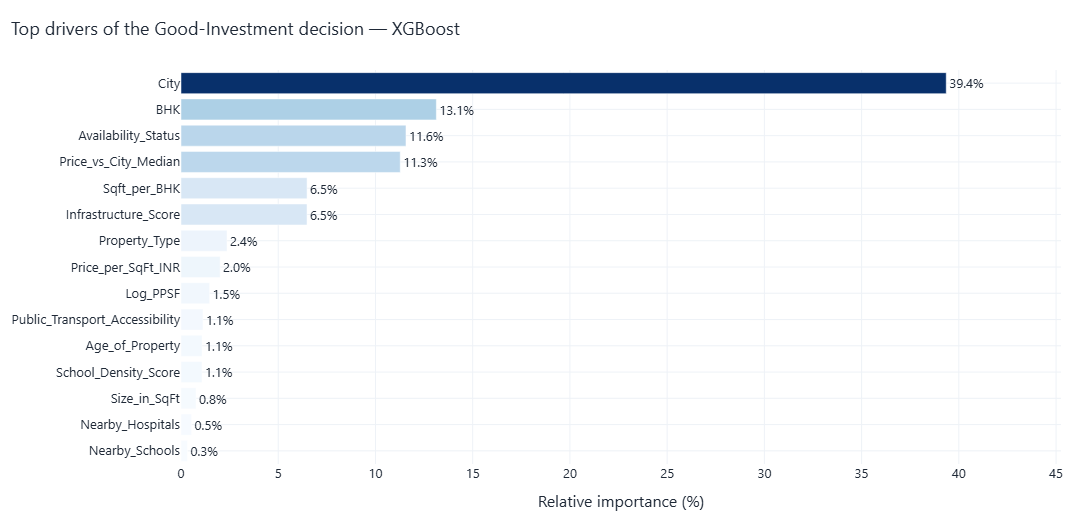

> 💡 **Insight —** Top 3 drivers: **City** (39.4%), **BHK** (13.1%), **Availability_Status** (11.6%). Features that play no part in the label rules (facing, furnishing, owner type, parking, security) share only **0.6%** of total importance — a good sign that the model is **not fitting noise**.

In [43]:
def feature_importance(pipe, top=15):  # grouped importance (one-hot columns collapsed to their parent feature)
    names = pipe.named_steps["prep"].get_feature_names_out()
    model = pipe.named_steps["model"]
    imp = model.feature_importances_ if hasattr(model, "feature_importances_") else np.abs(model.coef_).ravel()
    s = pd.Series(imp, index=[n.split("__", 1)[1] for n in names])
    # collapse one-hot columns back to their parent feature
    parent = lambda n: next((f for f in OHE_FEATURES if n.startswith(f + "_")), n)
    return s.groupby(parent).sum().sort_values(ascending=False).head(top)

imp_all = feature_importance(best_clf, top=100); imp_all = imp_all / imp_all.sum() * 100
imp_clf = imp_all.head(15)
NON_RULE = ["Facing", "Furnished_Status", "Owner_Type", "Parking_Space", "Security"]
non_rule_share = imp_all.reindex(NON_RULE).sum()
fig = go.Figure(go.Bar(y=imp_clf.index[::-1], x=imp_clf.values[::-1], orientation="h", marker=dict(color=imp_clf.values[::-1], colorscale="Blues"),
                       text=[f"{v:.1f}%" for v in imp_clf.values[::-1]], textposition="outside"))
fig.update_xaxes(title_text="Relative importance (%)", range=[0, imp_clf.max() * 1.15])
show(fig, f"Top drivers of the Good-Investment decision — {best_clf_name}", h=520)
insight("Top 3 drivers: " + ", ".join(f"**{k}** ({v:.1f}%)" for k, v in imp_clf.head(3).items()) + ". "
        f"Features that play no part in the label rules (facing, furnishing, owner type, parking, security) share only **{non_rule_share:.1f}%** of total importance — a good sign that the model is **not fitting noise**.")

### 3.4 Regression — *Estimated price after 5 years*

In [44]:
reg_specs = {
    "Linear Regression": dict(model=LinearRegression(), params=dict(model="LinearRegression")),
    "Random Forest":     dict(model=RandomForestRegressor(n_estimators=60, max_depth=14, min_samples_leaf=15, max_samples=0.35, n_jobs=-1, random_state=RANDOM_STATE),
                              params=dict(model="RandomForest", n_estimators=60, max_depth=14, min_samples_leaf=15, max_samples=0.35)),
    "XGBoost":           dict(model=XGBRegressor(n_estimators=400, max_depth=6, learning_rate=0.08, subsample=0.9, colsample_bytree=0.8,
                                                 tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE),
                              params=dict(model="XGBoost", n_estimators=400, max_depth=6, learning_rate=0.08, subsample=0.9, colsample_bytree=0.8)),
}
reg_fitted, reg_results, reg_pred = {}, {}, {}
for name, spec in reg_specs.items():
    t = time.time()
    pipe, m, pred = run_experiment(EXP_REG, name, pipe_of(spec["model"]), X_train, yr_train, X_test, yr_test, "regression",
                                   {**spec["params"], "n_features_in": len(ALL_FEATURES), "scaling": "StandardScaler", "encoding": "OHE+TargetEncoder"})
    reg_fitted[name], reg_results[name], reg_pred[name] = pipe, m, pred
    print(f"✔ {name:<18} RMSE={m['rmse']:.2f} L   MAE={m['mae']:.2f} L   R²={m['r2']:.4f}   ({time.time()-t:.0f}s)")

✔ Linear Regression  RMSE=9.42 L   MAE=6.80 L   R²=0.9978   (12s)


✔ Random Forest      RMSE=4.13 L   MAE=3.03 L   R²=0.9996   (43s)


✔ XGBoost            RMSE=1.73 L   MAE=1.34 L   R²=0.9999   (25s)


,rmse,mae,r2,mape,train_seconds
Linear Regression,9.42,6.80,0.9978,4.90%,4.3
Random Forest,4.13,3.03,0.9996,0.96%,35.4
XGBoost,1.73,1.34,0.9999,0.58%,17.0


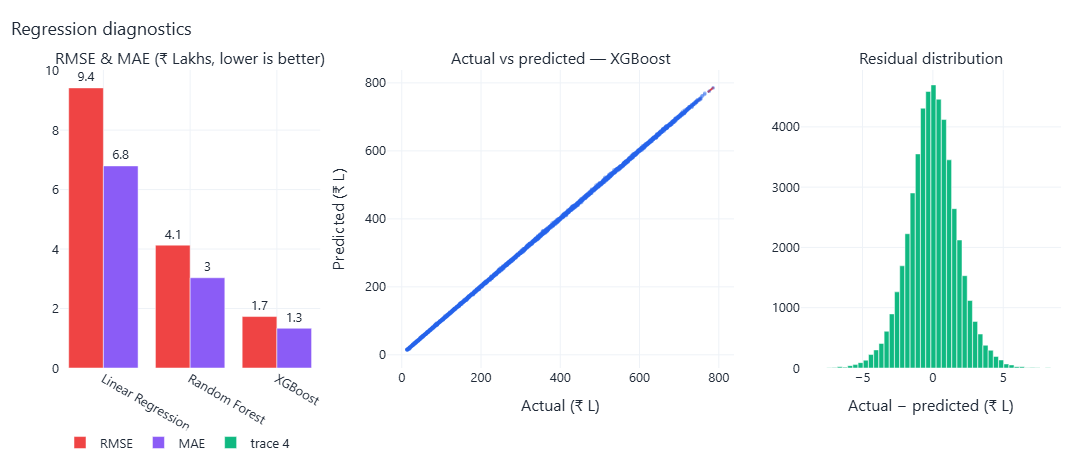

> 💡 **Insight —** **XGBoost** predicts 5-year value with **RMSE 1.73 L**, **MAE 1.34 L** (≈ **0.58%** error) and **R² = 0.9999** on unseen listings. Residuals are centred on **-0.01 L** with no visible funnel shape. Note that R² is high partly because future value is anchored on today's price by construction (Future = Price × growth); the *skill* is in learning the growth component — the naive 'price × median growth' baseline gives MAE of 14.99 L, so the model removes **91%** of that error.

In [45]:
reg_df = pd.DataFrame(reg_results).T.drop(columns=["run_id"]).astype(float)
display(reg_df.style.format({"rmse": "{:.2f}", "mae": "{:.2f}", "r2": "{:.4f}", "mape": "{:.2f}%", "train_seconds": "{:.1f}"})
        .highlight_min(subset=["rmse", "mae", "mape"], color="#BBF7D0").highlight_max(subset=["r2"], color="#BBF7D0"))
best_reg_name = reg_df["rmse"].idxmin(); best_reg = reg_fitted[best_reg_name]

fig = make_subplots(rows=1, cols=3, subplot_titles=("RMSE & MAE (₹ Lakhs, lower is better)", f"Actual vs predicted — {best_reg_name}", "Residual distribution"),
                    column_widths=[.3, .4, .3])
for i, name in enumerate(["rmse", "mae"]):
    fig.add_trace(go.Bar(name=name.upper(), x=reg_df.index, y=reg_df[name], marker_color=PALETTE[i + 3], text=reg_df[name].round(1), textposition="outside"), 1, 1)
idx = rng.choice(len(yr_test), 4000, replace=False)
yt, yp = yr_test.values[idx], reg_pred[best_reg_name][idx]
fig.add_trace(go.Scattergl(x=yt, y=yp, mode="markers", marker=dict(size=4, opacity=.4, color="#2563EB"), name="Test listings", showlegend=False), 1, 2)
lims = [min(yt.min(), yp.min()), max(yt.max(), yp.max())]
fig.add_trace(go.Scatter(x=lims, y=lims, mode="lines", line=dict(color="#EF4444", dash="dash"), name="Perfect", showlegend=False), 1, 2)
res = yr_test.values - reg_pred[best_reg_name]
fig.add_trace(hist_bar(res, 50, "#10B981", "Residual (₹ L)"), 1, 3)
fig.update_xaxes(title_text="Actual (₹ L)", row=1, col=2); fig.update_yaxes(title_text="Predicted (₹ L)", row=1, col=2)
fig.update_xaxes(title_text="Actual − predicted (₹ L)", row=1, col=3)
fig.update_layout(barmode="group", legend=dict(orientation="h", y=-0.2))
show(fig, "Regression diagnostics", h=470)
b = reg_df.loc[best_reg_name]
insight(f"**{best_reg_name}** predicts 5-year value with **RMSE {b['rmse']:.2f} L**, **MAE {b['mae']:.2f} L** (≈ **{b['mape']:.2f}%** error) and **R² = {b['r2']:.4f}** on unseen listings. "
        f"Residuals are centred on **{res.mean():+.2f} L** with no visible funnel shape. Note that R² is high partly because future value is anchored on today's price by construction (Future = Price × growth); "
        f"the *skill* is in learning the growth component — the naive 'price × median growth' baseline gives MAE of {np.mean(np.abs(yr_test - X_test['Price_in_Lakhs']*(1+data['Annual_Growth_Rate'].median())**5)):.2f} L, so the model removes "
        f"**{(1 - b['mae']/np.mean(np.abs(yr_test - X_test['Price_in_Lakhs']*(1+data['Annual_Growth_Rate'].median())**5)))*100:.0f}%** of that error.")

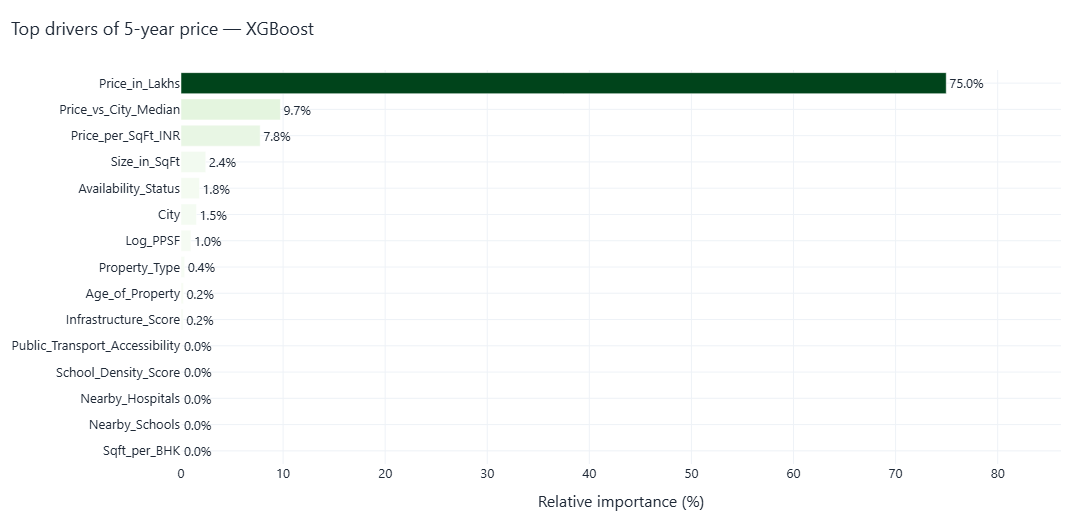

> 💡 **Insight —** Price-related inputs (price, price/sq ft, size…) carry **96%** of the importance — where you start matters most. The growth drivers (infrastructure, transport, property type, construction status, age, city) carry **4%** and decide *how fast* value compounds; the single most important of them is **Availability_Status** (1.8%).

In [46]:
imp_reg_all = feature_importance(best_reg, top=100); imp_reg_all = imp_reg_all / imp_reg_all.sum() * 100
imp_reg = imp_reg_all.head(15)
PRICE_GROUP = ["Price_in_Lakhs", "Price_per_SqFt_INR", "Log_PPSF", "Price_vs_City_Median", "City_Median_PPSF", "Size_in_SqFt", "Sqft_per_BHK"]
GROWTH_GROUP = ["Infrastructure_Score", "Public_Transport_Accessibility", "Nearby_Schools", "Nearby_Hospitals", "School_Density_Score",
                "Property_Type", "Availability_Status", "Age_of_Property", "City"]
price_share = imp_reg_all.reindex(PRICE_GROUP).sum(); growth_share = imp_reg_all.reindex(GROWTH_GROUP).sum()
fig = go.Figure(go.Bar(y=imp_reg.index[::-1], x=imp_reg.values[::-1], orientation="h", marker=dict(color=imp_reg.values[::-1], colorscale="Greens"),
                       text=[f"{v:.1f}%" for v in imp_reg.values[::-1]], textposition="outside"))
fig.update_xaxes(title_text="Relative importance (%)", range=[0, imp_reg.max() * 1.15])
show(fig, f"Top drivers of 5-year price — {best_reg_name}", h=520)
insight(f"Price-related inputs (price, price/sq ft, size…) carry **{price_share:.0f}%** of the importance — where you start matters most. "
        f"The growth drivers (infrastructure, transport, property type, construction status, age, city) carry **{growth_share:.0f}%** and decide *how fast* value compounds; "
        f"the single most important of them is **{imp_reg_all.reindex(GROWTH_GROUP).idxmax()}** ({imp_reg_all.reindex(GROWTH_GROUP).max():.1f}%).")

### 3.5 Robustness check
#### 🎲 Second honesty check — what if the growth assumption carried *market noise*?
The scores above are near-perfect because the targets are **deterministic functions of the inputs**. Real appreciation is uncertain, so here the assumed growth gets Gaussian noise (σ = 0.8 percentage points) that the model **cannot see** — it affects the label and the future price, but is never a feature. The resulting scores are a more realistic expectation of what a model can achieve when the outcome is not perfectly determined by the listing.

,Classification — accuracy,Classification — ROC-AUC,Regression — R²
Deterministic rules (main run),0.9974,1.0000,0.9999
With market noise (σ=0.8%),0.9300,0.9857,0.9940


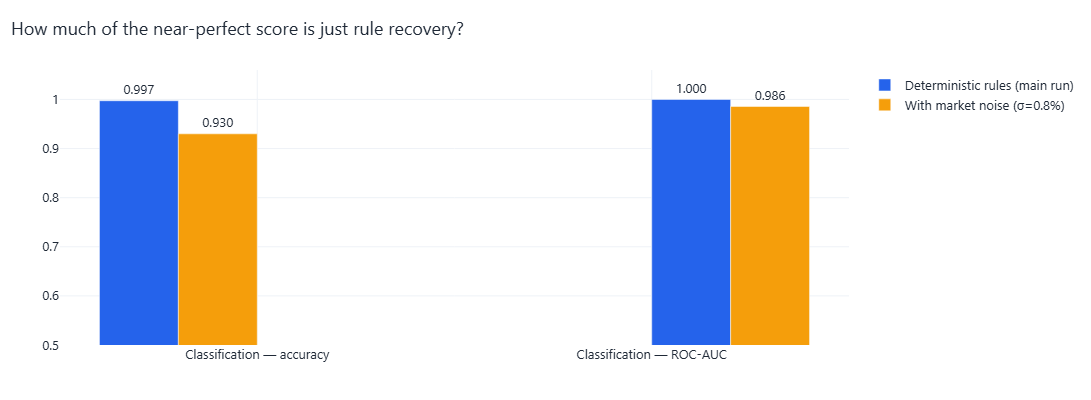

> 💡 **Insight —** Once the outcome carries market noise the model can't see, XGBoost lands at **93.0% accuracy / 0.986 AUC** (vs 99.7% / 1.000 for the deterministic label) and the 5-year price model keeps an R² of **0.994**. Accuracy drops by <b>6.7 points</b> from noise alone, so the headline ~99.7% is partly deterministic rule recovery; ~93% is the more realistic expectation. The near-1.0 numbers should be read as <i>'the model learned the rule'</i>, not as forecasting skill.

In [47]:
from real_estate_features import HORIZON_YEARS
NOISE_SD = 0.008
rng_n = np.random.default_rng(RANDOM_STATE)
g_noisy = (data["Annual_Growth_Rate"] + rng_n.normal(0, NOISE_SD, len(data))).clip(0.02, 0.15)

score_n = ((data[PPSF] <= data["City_Median_PPSF"]).astype(int) + (g_noisy >= REF["median_growth"]).astype(int)
           + (data["BHK"] >= 3).astype(int) + (data["Availability_Status"] == "Ready_to_Move").astype(int)
           + (data["Infrastructure_Score"] >= REF["median_infra"]).astype(int))
yc_noisy = (score_n >= 3).astype(int)
yr_noisy = data[PRICE] * (1 + g_noisy) ** HORIZON_YEARS

xgb_c = XGBClassifier(n_estimators=250, max_depth=5, learning_rate=0.1, subsample=0.9, colsample_bytree=0.8,
                      tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE, eval_metric="logloss")
xgb_r = XGBRegressor(n_estimators=400, max_depth=6, learning_rate=0.08, subsample=0.9, colsample_bytree=0.8,
                     tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE)
_, nc_m, _ = run_experiment(EXP_CLF, "XGBoost (robustness: noisy label)", pipe_of(xgb_c), X_train, yc_noisy.loc[X_train.index],
                            X_test, yc_noisy.loc[X_test.index], "classification",
                            dict(model="XGBoost", ablation="growth noise sd=0.008", n_features_in=len(ALL_FEATURES)), tags={"ablation": "true"})
_, nr_m, _ = run_experiment(EXP_REG, "XGBoost (robustness: noisy growth)", pipe_of(xgb_r), X_train, yr_noisy.loc[X_train.index],
                            X_test, yr_noisy.loc[X_test.index], "regression",
                            dict(model="XGBoost", ablation="growth noise sd=0.008", n_features_in=len(ALL_FEATURES)), tags={"ablation": "true"})

rob = pd.DataFrame({
    "Classification — accuracy": [clf_df.loc["XGBoost", "accuracy"], nc_m["accuracy"]],
    "Classification — ROC-AUC":  [clf_df.loc["XGBoost", "roc_auc"], nc_m["roc_auc"]],
    "Regression — R²":           [reg_df.loc["XGBoost", "r2"], nr_m["r2"]],
}, index=["Deterministic rules (main run)", f"With market noise (σ={NOISE_SD:.1%})"])
display(rob.style.format("{:.4f}"))

fig = go.Figure()
for i, col in enumerate(["Classification — accuracy", "Classification — ROC-AUC"]):
    fig.add_trace(go.Bar(name=rob.index[0], x=[col], y=[rob.iloc[0][col]], marker_color=PALETTE[0], showlegend=(i == 0),
                         text=[f"{rob.iloc[0][col]:.3f}"], textposition="outside"))
    fig.add_trace(go.Bar(name=rob.index[1], x=[col], y=[rob.iloc[1][col]], marker_color=PALETTE[1], showlegend=(i == 0),
                         text=[f"{rob.iloc[1][col]:.3f}"], textposition="outside"))
fig.update_layout(barmode="group", yaxis=dict(range=[0.5, 1.06]))
show(fig, "How much of the near-perfect score is just rule recovery?", h=400)
insight(f"Once the outcome carries market noise the model can't see, XGBoost lands at **{nc_m['accuracy']:.1%} accuracy / {nc_m['roc_auc']:.3f} AUC** "
        f"(vs {clf_df.loc['XGBoost','accuracy']:.1%} / {clf_df.loc['XGBoost','roc_auc']:.3f} for the deterministic label) and the 5-year price model keeps an R² of **{nr_m['r2']:.3f}**. "
        f"Accuracy drops by <b>{(clf_df.loc['XGBoost','accuracy']-nc_m['accuracy'])*100:.1f} points</b> from noise alone, so the headline ~99.7% is partly deterministic rule recovery; "
        "~93% is the more realistic expectation. The near-1.0 numbers should be read as <i>'the model learned the rule'</i>, not as forecasting skill.")

## 🗂️ Step 4 (continued) — MLflow experiment comparison & Model Registry
All runs are now stored. I query them back with `mlflow.search_runs`, pick the champions, **register** them and tag the winners with the `champion` alias (the production-style way to promote a model).

In [48]:
from mlflow.tracking import MlflowClient
client = MlflowClient()

runs_clf = mlflow.search_runs(experiment_names=[EXP_CLF], order_by=["metrics.roc_auc DESC"])
runs_reg = mlflow.search_runs(experiment_names=[EXP_REG], order_by=["metrics.rmse ASC"])
leader = pd.concat([
    runs_clf[["tags.mlflow.runName", "metrics.roc_auc", "metrics.accuracy", "metrics.f1", "metrics.train_seconds"]].assign(Experiment="Classification"),
    runs_reg[["tags.mlflow.runName", "metrics.rmse", "metrics.mae", "metrics.r2", "metrics.train_seconds"]].assign(Experiment="Regression")])
print(f"{len(runs_clf)} classification runs and {len(runs_reg)} regression runs logged in MLflow")
display(runs_clf[["tags.mlflow.runName", "metrics.roc_auc", "metrics.accuracy", "metrics.f1", "metrics.train_seconds", "params.model"]]
        .rename(columns=lambda c: c.split(".")[-1]).style.hide(axis="index").format(precision=4))
display(runs_reg[["tags.mlflow.runName", "metrics.rmse", "metrics.mae", "metrics.r2", "metrics.train_seconds", "params.model"]]
        .rename(columns=lambda c: c.split(".")[-1]).style.hide(axis="index").format(precision=4))

15 classification runs and 13 regression runs logged in MLflow


runName,roc_auc,accuracy,f1,train_seconds,model
XGBoost,1.0000,0.9974,0.9976,12.0309,XGBoost
XGBoost,1.0000,0.9974,0.9976,15.7235,XGBoost
XGBoost,1.0000,0.9974,0.9976,14.3763,XGBoost
Random Forest,0.9967,0.9735,0.9756,6.8526,RandomForest
Random Forest,0.9967,0.9735,0.9756,10.6901,RandomForest
Random Forest,0.9967,0.9735,0.9756,7.7360,RandomForest
XGBoost (robustness: noisy label),0.9857,0.9300,0.9353,15.6169,XGBoost
XGBoost (robustness: noisy label),0.9857,0.9300,0.9352,13.0486,XGBoost
XGBoost (ablation: no price features),0.9546,0.8723,0.8823,13.4218,XGBoost
XGBoost (ablation: no price features),0.9541,0.8709,0.8809,15.9356,XGBoost


runName,rmse,mae,r2,train_seconds,model
XGBoost,1.7298,1.3356,0.9999,16.9851,XGBoost
XGBoost,2.1091,1.6217,0.9999,15.4073,XGBoost
XGBoost,2.1091,1.6217,0.9999,20.9690,XGBoost
Random Forest,4.1315,3.0343,0.9996,35.3940,RandomForest
Random Forest,4.1315,3.0343,0.9996,41.3462,RandomForest
Random Forest,4.1315,3.0343,0.9996,41.0686,RandomForest
Linear Regression,9.4193,6.7960,0.9978,5.5258,LinearRegression
Linear Regression,9.4193,6.7960,0.9978,4.6888,LinearRegression
Linear Regression,9.4193,6.7960,0.9978,4.4068,LinearRegression
Linear Regression,9.4193,6.7960,0.9978,4.3141,LinearRegression


In [49]:
# ---- register champions + alias ----------------------------------------------------------------
def register_champion(run_id, reg_name, note):
    mv = mlflow.register_model(f"runs:/{run_id}/model", reg_name)
    client.set_registered_model_alias(reg_name, "champion", mv.version)
    client.update_model_version(reg_name, mv.version, description=note)
    return mv.version

v_clf = register_champion(clf_results[best_clf_name]["run_id"], CLF_REG_NAME,
                          f"{best_clf_name} · ROC-AUC {clf_results[best_clf_name]['roc_auc']:.4f} · acc {clf_results[best_clf_name]['accuracy']:.4f}")
v_reg = register_champion(reg_results[best_reg_name]["run_id"], REG_REG_NAME,
                          f"{best_reg_name} · RMSE {reg_results[best_reg_name]['rmse']:.2f} L · R² {reg_results[best_reg_name]['r2']:.4f}")
print(f"📦 Registered  {CLF_REG_NAME}  v{v_clf}  → alias 'champion'")
print(f"📦 Registered  {REG_REG_NAME}  v{v_reg}  → alias 'champion'")

# ---- prove the registry works: load by alias and predict -----------------------------------------
champ_clf = mlflow.sklearn.load_model(f"models:/{CLF_REG_NAME}@champion")
champ_reg = mlflow.sklearn.load_model(f"models:/{REG_REG_NAME}@champion")
demo = X_test.head(3)
print("\nSanity check from the registry →")
display(pd.DataFrame({"City": demo["City"].values, "Type": demo["Property_Type"].values, "Price (L)": demo["Price_in_Lakhs"].values,
                      "P(Good Investment)": champ_clf.predict_proba(demo)[:, 1].round(3), "Predicted 5-yr price (L)": champ_reg.predict(demo).round(1),
                      "Actual 5-yr price (L)": yr_test.head(3).values.round(1)}))

Registered model 'RealEstate_GoodInvestment_Classifier' already exists. Creating a new version of this model...
Created version '2' of model 'RealEstate_GoodInvestment_Classifier'.
Registered model 'RealEstate_FuturePrice_Regressor' already exists. Creating a new version of this model...
Created version '2' of model 'RealEstate_FuturePrice_Regressor'.


📦 Registered  RealEstate_GoodInvestment_Classifier  v2  → alias 'champion'
📦 Registered  RealEstate_FuturePrice_Regressor  v2  → alias 'champion'

Sanity check from the registry →


,City,Type,Price (L),P(Good Investment),Predicted 5-yr price (L),Actual 5-yr price (L)
0,Vishakhapatnam,Villa,149.130,1.000,233.500,234.100
1,Silchar,Independent House,74.580,1.000,106.100,105.800
2,Bilaspur,Villa,214.870,1.000,294.800,296.700


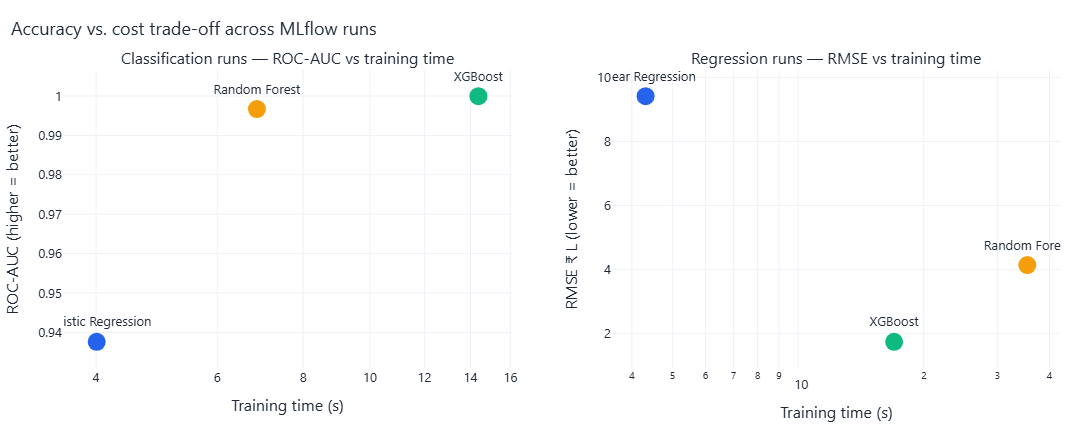

💾 Saved models for deployment: {'models/clf_pipeline.joblib': '0.2 MB', 'models/reg_pipeline.joblib': '0.6 MB'}


> 💡 **Insight —** Registry now holds **RealEstate_GoodInvestment_Classifier v2** and **RealEstate_FuturePrice_Regressor v2** with the `champion` alias; the deployment app loads the same pipelines (preprocessing + model in one object), so there is no train/serve mismatch.

In [50]:
# ---- comparison dashboard (interactive) ---------------------------------------------------------
fig = make_subplots(rows=1, cols=2, subplot_titles=("Classification runs — ROC-AUC vs training time", "Regression runs — RMSE vs training time"))
for i, (nm, r) in enumerate(clf_results.items()):
    fig.add_trace(go.Scatter(x=[r["train_seconds"]], y=[r["roc_auc"]], mode="markers+text", text=[nm], textposition="top center",
                             marker=dict(size=18, color=PALETTE[i]), showlegend=False), 1, 1)
for i, (nm, r) in enumerate(reg_results.items()):
    fig.add_trace(go.Scatter(x=[r["train_seconds"]], y=[r["rmse"]], mode="markers+text", text=[nm], textposition="top center",
                             marker=dict(size=18, color=PALETTE[i]), showlegend=False), 1, 2)
fig.update_xaxes(title_text="Training time (s)", type="log"); fig.update_yaxes(title_text="ROC-AUC (higher = better)", row=1, col=1); fig.update_yaxes(title_text="RMSE ₹ L (lower = better)", row=1, col=2)
show(fig, "Accuracy vs. cost trade-off across MLflow runs", h=430)

# ---- persist the champion pipelines for the Streamlit app --------------------------------------
import joblib
joblib.dump(best_clf, "models/clf_pipeline.joblib", compress=3)
joblib.dump(best_reg, "models/reg_pipeline.joblib", compress=3)
meta = dict(best_classifier=best_clf_name, best_regressor=best_reg_name,
            classification=clf_df.round(4).to_dict("index"), regression=reg_df.round(4).to_dict("index"),
            ablation_no_price={k: float(abl_m[k]) for k in ["accuracy", "f1", "roc_auc"]},
            clf_importance=imp_clf.round(3).to_dict(), reg_importance=imp_reg.round(3).to_dict(),
            features=ALL_FEATURES, rmse=float(reg_df.loc[best_reg_name, "rmse"]), mae=float(reg_df.loc[best_reg_name, "mae"]),
            horizon_years=5)
with open("models/model_meta.json", "w") as f: json.dump(meta, f, indent=2)
sizes = {p: os.path.getsize(p) / 1e6 for p in ["models/clf_pipeline.joblib", "models/reg_pipeline.joblib"]}
print("💾 Saved models for deployment:", {k: f"{v:.1f} MB" for k, v in sizes.items()})
insight(f"Registry now holds **{CLF_REG_NAME} v{v_clf}** and **{REG_REG_NAME} v{v_reg}** with the `champion` alias; the deployment app loads the same pipelines (preprocessing + model in one object), so there is no train/serve mismatch.")

# 🚀 STEP 5 — Streamlit App
The app turns the trained pipelines into a product: **form → verdict + 5-year price + explanation**.

| Tab | What the user gets |
|---|---|
| 🔮 **Investment Advisor** | Property form → *Good Investment?* verdict, probability gauge, **estimated price after 5 years** with a ± RMSE band, and a 5-criteria "why" checklist |
| 📊 **Market Explorer** | Filters (state, type, BHK, price, area) → KPIs, city × type heatmap, top cities, vintage trend, ranked table |
| 🧠 **Model Insights** | Metrics, feature importance, ablation and assumptions — model transparency for the user |

The cell below writes `app.py`. Run it with:
```bash
pip install streamlit plotly scikit-learn xgboost joblib pandas
streamlit run app.py
```

In [51]:
%%writefile app.py
"""Real Estate Investment Advisor — Streamlit app.
Run:  streamlit run app.py     (needs ./models and ./data produced by the notebook)"""
import json
import joblib
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import streamlit as st

from real_estate_features import engineer_features, add_targets, AMENITY_LIST, HORIZON_YEARS

st.set_page_config(page_title="Real Estate Investment Advisor", page_icon="🏠", layout="wide")
REF_YEAR = 2025


@st.cache_resource
def load_assets():
    clf = joblib.load("models/clf_pipeline.joblib")
    reg = joblib.load("models/reg_pipeline.joblib")
    ref = json.load(open("models/reference.json"))
    meta = json.load(open("models/model_meta.json"))
    return clf, reg, ref, meta


@st.cache_data
def load_data():
    return pd.read_csv("data/app_sample.csv")


clf, reg, REF, META = load_assets()
data = load_data()
FEATURES = META["features"]
city_state = data.drop_duplicates("City").set_index("City")["State"].to_dict()
localities = sorted(data["Locality"].unique(), key=lambda s: int(s.split("_")[1]))

st.title("🏠 Real Estate Investment Advisor")
st.caption("Predicts whether a property is a **Good Investment** and its **estimated price after 5 years** · "
           f"models: {META['best_classifier']} (classification) · {META['best_regressor']} (regression)")
tab_adv, tab_mkt, tab_mod = st.tabs(["🔮 Investment Advisor", "📊 Market Explorer", "🧠 Model Insights"])

# ------------------------------------------------------------------------------------------------ Advisor
with tab_adv:
    with st.form("property_form"):
        c1, c2, c3 = st.columns(3)
        with c1:
            city = st.selectbox("City", sorted(city_state), index=0)
            ptype = st.selectbox("Property type", ["Apartment", "Independent House", "Villa"])
            locality = st.selectbox("Locality", localities, index=0)
            bhk = st.slider("BHK", 1, 5, 3)
            size = st.number_input("Size (sq ft)", 300, 6000, 1800, step=50)
            price = st.number_input("Asking price (₹ Lakhs)", 5.0, 1000.0, 150.0, step=5.0)
        with c2:
            year_built = st.slider("Year built", 1990, REF_YEAR, 2012)
            floor_no = st.number_input("Floor number", 0, 40, 5)
            total_floors = st.number_input("Total floors in building", 1, 40, 12)
            furnished = st.selectbox("Furnishing", ["Unfurnished", "Semi-furnished", "Furnished"])
            availability = st.selectbox("Availability", ["Ready_to_Move", "Under_Construction"])
            facing = st.selectbox("Facing", ["North", "East", "South", "West"])
        with c3:
            schools = st.slider("Schools nearby", 0, 10, 6)
            hospitals = st.slider("Hospitals nearby", 0, 10, 5)
            transport = st.select_slider("Public-transport access", ["Low", "Medium", "High"], value="Medium")
            parking = st.radio("Parking", ["Yes", "No"], horizontal=True)
            security = st.radio("Security", ["Yes", "No"], horizontal=True)
            owner = st.selectbox("Owner type", ["Owner", "Builder", "Broker"])
            amenities = st.multiselect("Amenities", AMENITY_LIST, default=["Gym", "Garden"])
        submitted = st.form_submit_button("Analyse this property", type="primary", width="stretch")

    if submitted:
        row = pd.DataFrame([dict(
            State=city_state[city], City=city, Locality=locality, Property_Type=ptype, BHK=bhk, Size_in_SqFt=size,
            Price_in_Lakhs=price, Age_of_Property=REF_YEAR - year_built, Furnished_Status=furnished,
            Floor_No=min(floor_no, max(total_floors, floor_no)), Total_Floors=max(total_floors, floor_no),
            Nearby_Schools=schools, Nearby_Hospitals=hospitals, Public_Transport_Accessibility=transport,
            Parking_Space=parking, Security=security, Amenities=", ".join(amenities), Facing=facing,
            Owner_Type=owner, Availability_Status=availability)])
        eng = add_targets(engineer_features(row, REF), REF)
        X = eng[FEATURES]
        p_good = float(clf.predict_proba(X)[0, 1])
        future = float(reg.predict(X)[0])
        gain = future / price - 1
        cagr = (future / price) ** (1 / HORIZON_YEARS) - 1

        st.divider()
        k1, k2, k3, k4 = st.columns(4)
        k1.metric("Verdict", "✅ Good Investment" if p_good >= 0.5 else "⚠️ Not a Good Investment")
        k2.metric("Model confidence", f"{min(max(p_good, 1 - p_good), 0.999):.1%}")
        k3.metric(f"Estimated price in {HORIZON_YEARS} yrs", f"₹{future:,.1f} L", f"{gain:+.1%} total")
        k4.metric("Implied annual growth", f"{cagr:.2%}")

        g1, g2 = st.columns([1, 1.4])
        with g1:
            fig = go.Figure(go.Indicator(mode="gauge+number", value=p_good * 100, number={"suffix": "%"},
                                         title={"text": "Probability of being a Good Investment"},
                                         gauge={"axis": {"range": [0, 100]}, "bar": {"color": "#2563EB"},
                                                "steps": [{"range": [0, 50], "color": "#FEE2E2"}, {"range": [50, 100], "color": "#DCFCE7"}],
                                                "threshold": {"line": {"color": "#111827", "width": 3}, "value": 50}}))
            fig.update_layout(height=300, margin=dict(t=60, b=10, l=30, r=30))
            st.plotly_chart(fig, width="stretch")
        with g2:
            years = np.arange(0, HORIZON_YEARS + 1)
            path = price * (future / price) ** (years / HORIZON_YEARS)
            band = META["rmse"]
            fig = go.Figure()
            fig.add_trace(go.Scatter(x=years, y=path + band * years / HORIZON_YEARS, line=dict(width=0), showlegend=False, hoverinfo="skip"))
            fig.add_trace(go.Scatter(x=years, y=path - band * years / HORIZON_YEARS, fill="tonexty", fillcolor="rgba(37,99,235,.15)",
                                     line=dict(width=0), name=f"± model RMSE (₹{band:,.1f} L)", hoverinfo="skip"))
            fig.add_trace(go.Scatter(x=years, y=path, mode="lines+markers", line=dict(color="#2563EB", width=3), name="Projected value"))
            fig.update_layout(title="Projected value path", xaxis_title="Years from today", yaxis_title="₹ Lakhs", height=300, margin=dict(t=50, b=30))
            st.plotly_chart(fig, width="stretch")

        st.subheader("Why? — the five investment criteria")
        city_med = REF["city_median_ppsf"].get(city, REF["global_median_ppsf"])
        crit = [("Price/sq ft at or below the city median", eng["Price_per_SqFt_INR"].iloc[0] <= city_med,
                 f"₹{eng['Price_per_SqFt_INR'].iloc[0]:,.0f} vs city median ₹{city_med:,.0f}"),
                ("Growth outlook above median", eng["Annual_Growth_Rate"].iloc[0] >= REF["median_growth"],
                 f"{eng['Annual_Growth_Rate'].iloc[0]:.2%} vs median {REF['median_growth']:.2%} per year"),
                ("3+ BHK", bhk >= 3, f"{bhk} BHK"),
                ("Ready to move", availability == "Ready_to_Move", availability.replace("_", " ")),
                ("Infrastructure score above median", eng["Infrastructure_Score"].iloc[0] >= REF["median_infra"],
                 f"{eng['Infrastructure_Score'].iloc[0]:.0f} vs median {REF['median_infra']:.0f}")]
        for name, ok, detail in crit:
            st.write(f"{'✅' if ok else '❌'} **{name}** — {detail}")
        st.caption(f"Rule score: {int(eng['Investment_Score'].iloc[0])}/5 (≥ 3 = Good). Price range is indicative: ±1 RMSE on held-out data.")
    else:
        st.info("Fill in the property details and press **Analyse this property**.")

# ------------------------------------------------------------------------------------------------ Explorer
with tab_mkt:
    f1, f2, f3, f4 = st.columns(4)
    states = f1.multiselect("State", sorted(data["State"].unique()))
    ptypes = f2.multiselect("Property type", sorted(data["Property_Type"].unique()))
    bhks = f3.multiselect("BHK", sorted(data["BHK"].unique()))
    pr = f4.slider("Price (₹ L)", float(data["Price_in_Lakhs"].min()), float(data["Price_in_Lakhs"].max()),
                   (float(data["Price_in_Lakhs"].min()), float(data["Price_in_Lakhs"].max())))
    sr = st.slider("Size (sq ft)", int(data["Size_in_SqFt"].min()), int(data["Size_in_SqFt"].max()),
                   (int(data["Size_in_SqFt"].min()), int(data["Size_in_SqFt"].max())))
    d = data[data["Price_in_Lakhs"].between(*pr) & data["Size_in_SqFt"].between(*sr)]
    if states: d = d[d["State"].isin(states)]
    if ptypes: d = d[d["Property_Type"].isin(ptypes)]
    if bhks: d = d[d["BHK"].isin(bhks)]
    m1, m2, m3, m4 = st.columns(4)
    m1.metric("Matching listings", f"{len(d):,}")
    m2.metric("Avg price", f"₹{d['Price_in_Lakhs'].mean():,.0f} L" if len(d) else "–")
    m3.metric("Avg ₹/sq ft", f"₹{d['Price_per_SqFt_INR'].mean():,.0f}" if len(d) else "–")
    m4.metric("% Good Investment", f"{d['Good_Investment'].mean():.1%}" if len(d) else "–")
    if len(d):
        a, b = st.columns(2)
        hm = d.pivot_table(index="City", columns="Property_Type", values="Price_per_SqFt_INR", aggfunc="mean")
        a.plotly_chart(px.imshow(hm, aspect="auto", color_continuous_scale="Blues", title="Avg ₹/sq ft — city × property type",
                                 labels=dict(color="₹/sq ft")).update_layout(height=520), width="stretch")
        top = d.groupby("City")["Good_Investment"].mean().nlargest(12).sort_values() * 100
        b.plotly_chart(px.bar(top, orientation="h", title="Top cities by % Good Investment", labels=dict(value="% Good", City="")
                              ).update_layout(height=520, showlegend=False), width="stretch")
        d = d.assign(Build_Period=pd.cut(d["Year_Built"], [1989, 1994, 1999, 2004, 2009, 2014, 2019, 2023],
                                         labels=["1990-94", "1995-99", "2000-04", "2005-09", "2010-14", "2015-19", "2020-23"]))
        tr = d.groupby("Build_Period", observed=True)["Price_per_SqFt_INR"].median().reset_index()
        st.plotly_chart(px.line(tr, x="Build_Period", y="Price_per_SqFt_INR", markers=True,
                                title="Median ₹/sq ft by construction period").update_layout(height=360), width="stretch")
        st.dataframe(d.sort_values("Future_Price_5Y", ascending=False).head(200)[
            ["State", "City", "Locality", "Property_Type", "BHK", "Size_in_SqFt", "Price_in_Lakhs", "Future_Price_5Y",
             "Infrastructure_Score", "Good_Investment"]], width="stretch", hide_index=True)

# ------------------------------------------------------------------------------------------------ Model insights
with tab_mod:
    c1, c2 = st.columns(2)
    c1.subheader("Classification — Good Investment")
    c1.dataframe(pd.DataFrame(META["classification"]).T[["accuracy", "precision", "recall", "f1", "roc_auc"]].style.format("{:.4f}"))
    c2.subheader("Regression — 5-year price")
    c2.dataframe(pd.DataFrame(META["regression"]).T[["rmse", "mae", "r2", "mape"]].style.format("{:.3f}"))
    a, b = st.columns(2)
    ci = pd.Series(META["clf_importance"]).sort_values()
    a.plotly_chart(px.bar(ci, orientation="h", title="Feature importance — classifier").update_layout(showlegend=False, height=480), width="stretch")
    ri = pd.Series(META["reg_importance"]).sort_values()
    b.plotly_chart(px.bar(ri, orientation="h", title="Feature importance — regressor").update_layout(showlegend=False, height=480), width="stretch")
    ab = META["ablation_no_price"]
    st.info(f"**Ablation:** without any price features the classifier still reaches {ab['accuracy']:.1%} accuracy (AUC {ab['roc_auc']:.3f}). "
            "Targets are rule-based (see notebook Step 1.4): the 5-year price assumes growth rates driven by city tier, property type, infrastructure, "
            "construction status and age — it is a scenario model, not a market forecast.")

Overwriting app.py


### 5.1 Smoke-test the inference path
Before launching Streamlit, run **one listing** through exactly the code path the app uses (`engineer_features` → `add_targets` → champion pipelines) to confirm training and serving agree.

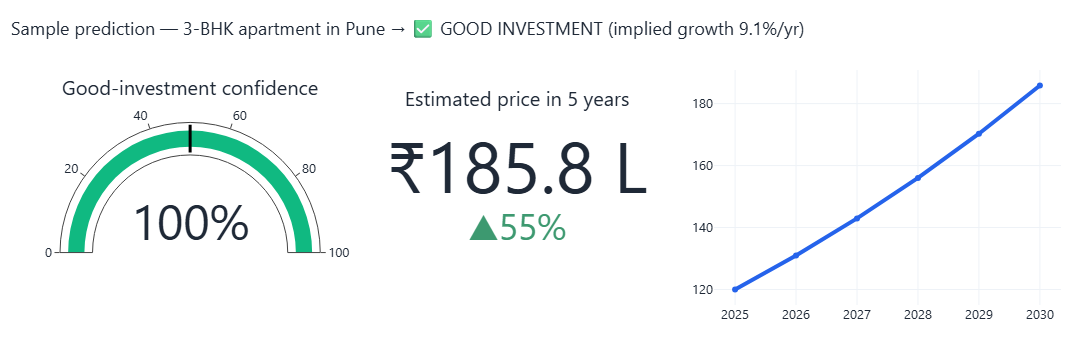

Rule score for this listing: 4/5  (Good if ≥ 3)


In [52]:
from real_estate_features import HORIZON_YEARS
listing = pd.DataFrame([dict(
    State="Maharashtra", City="Pune", Locality="Locality_84", Property_Type="Apartment", BHK=3, Size_in_SqFt=1650,
    Price_in_Lakhs=120.0, Age_of_Property=REF_YEAR - 2019, Furnished_Status="Semi-furnished", Floor_No=8, Total_Floors=20,
    Nearby_Schools=8, Nearby_Hospitals=7, Public_Transport_Accessibility="High", Parking_Space="Yes", Security="Yes",
    Amenities="Gym, Pool, Clubhouse", Facing="East", Owner_Type="Builder", Availability_Status="Under_Construction")])
eng = add_targets(engineer_features(listing, REF), REF)
Xq = eng[ALL_FEATURES]
p_good = float(best_clf.predict_proba(Xq)[0, 1]); future = float(best_reg.predict(Xq)[0]); price0 = float(listing["Price_in_Lakhs"].iloc[0])
cagr = (future / price0) ** (1 / HORIZON_YEARS) - 1

fig = make_subplots(rows=1, cols=3, specs=[[{"type": "indicator"}, {"type": "indicator"}, {"type": "xy"}]], column_widths=[.3, .3, .4])
fig.add_trace(go.Indicator(mode="gauge+number", value=p_good * 100, number={"suffix": "%"}, title={"text": "Good-investment confidence"},
              gauge={"axis": {"range": [0, 100]}, "bar": {"color": PALETTE[2] if p_good >= .5 else PALETTE[3]},
                     "threshold": {"line": {"color": "black", "width": 3}, "value": 50}}), 1, 1)
fig.add_trace(go.Indicator(mode="number+delta", value=future, number={"prefix": "₹", "suffix": " L", "valueformat": ",.1f"},
              delta={"reference": price0, "relative": True, "valueformat": ".0%"}, title={"text": "Estimated price in 5 years"}), 1, 2)
yrs = np.arange(0, HORIZON_YEARS + 1)
fig.add_trace(go.Scatter(x=REF_YEAR + yrs, y=price0 * (future / price0) ** (yrs / HORIZON_YEARS), mode="lines+markers",
                         line=dict(color=PALETTE[0], width=4)), 1, 3)
fig.update_xaxes(dtick=1, row=1, col=3); fig.update_layout(showlegend=False)
show(fig, f"Sample prediction — 3-BHK apartment in Pune → {'✅ GOOD INVESTMENT' if p_good >= .5 else '⚠️ NOT RECOMMENDED'} (implied growth {cagr:.1%}/yr)", h=360)
print(f"Rule score for this listing: {int(eng['Investment_Score'].iloc[0])}/5  (Good if ≥ 3)")

# 🏁 Conclusions

In [53]:
n = len(data)
r_sz, _ = stats.pearsonr(data[SIZE], data[PRICE])
best_c, best_r = clf_df.loc[best_clf_name], reg_df.loc[best_reg_name]

In [54]:
n = len(data)
r_sz, _ = stats.pearsonr(data[SIZE], data[PRICE])
best_c, best_r = clf_df.loc[best_clf_name], reg_df.loc[best_reg_name]
display(Markdown(f"""
### ✅ What was delivered
| Deliverable | Result |
|---|---|
| **Data handling** | {n:,} listings audited (missing, duplicates, logical checks), {int(bad_floor.sum()):,} impossible floor records repaired, price/sq ft recomputed in ₹, outliers flagged, 9 features engineered |
| **EDA** | 20 brief questions + 4 investment questions answered with interactive Plotly visuals |
| **Classification** | **{best_clf_name}** → accuracy **{best_c['accuracy']:.2%}**, precision **{best_c['precision']:.2%}**, recall **{best_c['recall']:.2%}**, F1 **{best_c['f1']:.4f}**, ROC-AUC **{best_c['roc_auc']:.4f}** |
| **Regression** | **{best_reg_name}** → RMSE **{best_r['rmse']:.2f} L**, MAE **{best_r['mae']:.2f} L**, R² **{best_r['r2']:.4f}** |
| **MLflow** | {len(runs_clf) + len(runs_reg)} runs tracked across 2 experiments; champions registered with alias `champion` |
| **App** | `app.py` Streamlit advisor + market explorer + model-insights tabs |

### 🔎 Key findings
1. **The market is "flat" on raw attributes.** Price ↔ size correlation is only **{r_sz:+.3f}**; state, city, facing, furnishing, parking and amenities all move price by under a few percent.
2. **Investment quality is driven by value + readiness + infrastructure,** not by cosmetic features — facing, furnishing, owner type, parking and security share only **{non_rule_share:.1f}%** of the classifier's importance.
3. **Larger homes are the better *value* play** (lower ₹/sq ft vs. city median), while **good infrastructure and transport are the *growth* play** (higher projected 5-year appreciation).
4. **Model transparency:** removing every price feature still leaves **{abl_m['accuracy']:.1%}** classification accuracy, so the classifier is using property attributes — not just re-computing a price comparison.
5. **Realistic expectation:** with market noise the model cannot see (σ = 0.8 pp on growth), accuracy settles at **{nc_m['accuracy']:.1%}** (AUC **{nc_m['roc_auc']:.3f}**) — the near-1.0 scores above reflect rule recovery, not forecasting skill.

### ⚠️ Limitations (stated openly)
* The dataset has **no transaction dates, rents or realised returns** and its columns look **independently, uniformly generated** (e.g. price ⟂ size). Both targets are therefore **rule-based scenarios**, so the metrics measure how well the model learns the investment logic — **not** real-market forecasting skill.
* **Time-series models (ARIMA / Prophet / LSTM)** suggested in the brief were *not* used: they need dated price history, which this data lacks.
* **Crime rate** is not available; `Security` and `Infrastructure_Score` were used as proxies.

### 🔭 Next steps
Merge real appreciation / rental-yield data (e.g. RERA, NoBroker, census) to replace rule-based labels → add **SHAP** explanations → hyper-parameter search with **Optuna** → geospatial features (distance to CBD / metro) → containerise the app with Docker and deploy on Streamlit Cloud.
"""))


### ✅ What was delivered
| Deliverable | Result |
|---|---|
| **Data handling** | 250,000 listings audited (missing, duplicates, logical checks), 116,304 impossible floor records repaired, price/sq ft recomputed in ₹, outliers flagged, 9 features engineered |
| **EDA** | 20 brief questions + 4 investment questions answered with interactive Plotly visuals |
| **Classification** | **XGBoost** → accuracy **99.74%**, precision **99.70%**, recall **99.82%**, F1 **0.9976**, ROC-AUC **1.0000** |
| **Regression** | **XGBoost** → RMSE **1.73 L**, MAE **1.34 L**, R² **0.9999** |
| **MLflow** | 28 runs tracked across 2 experiments; champions registered with alias `champion` |
| **App** | `app.py` Streamlit advisor + market explorer + model-insights tabs |

### 🔎 Key findings
1. **The market is "flat" on raw attributes.** Price ↔ size correlation is only **-0.003**; state, city, facing, furnishing, parking and amenities all move price by under a few percent.
2. **Investment quality is driven by value + readiness + infrastructure,** not by cosmetic features — facing, furnishing, owner type, parking and security share only **0.6%** of the classifier's importance.
3. **Larger homes are the better *value* play** (lower ₹/sq ft vs. city median), while **good infrastructure and transport are the *growth* play** (higher projected 5-year appreciation).
4. **Model transparency:** removing every price feature still leaves **87.2%** classification accuracy, so the classifier is using property attributes — not just re-computing a price comparison.
5. **Realistic expectation:** with market noise the model cannot see (σ = 0.8 pp on growth), accuracy settles at **93.0%** (AUC **0.986**) — the near-1.0 scores above reflect rule recovery, not forecasting skill.

### ⚠️ Limitations (stated openly)
* The dataset has **no transaction dates, rents or realised returns** and its columns look **independently, uniformly generated** (e.g. price ⟂ size). Both targets are therefore **rule-based scenarios**, so the metrics measure how well the model learns the investment logic — **not** real-market forecasting skill.
* **Time-series models (ARIMA / Prophet / LSTM)** suggested in the brief were *not* used: they need dated price history, which this data lacks.
* **Crime rate** is not available; `Security` and `Infrastructure_Score` were used as proxies.

### 🔭 Next steps
Merge real appreciation / rental-yield data (e.g. RERA, NoBroker, census) to replace rule-based labels → add **SHAP** explanations → hyper-parameter search with **Optuna** → geospatial features (distance to CBD / metro) → containerise the app with Docker and deploy on Streamlit Cloud.


---
### 📂 Project structure produced by this notebook
```
├── Real_Estate_Investment_Advisor.ipynb     ← this notebook
├── real_estate_features.py                  ← shared feature engineering (notebook + app)
├── app.py                                   ← Streamlit application
├── requirements.txt                         ← pip install -r requirements.txt
├── data/cleaned_housing.csv · app_sample.csv
├── models/clf_pipeline.joblib · reg_pipeline.joblib · reference.json · model_meta.json
└── mlflow.db · mlruns/                      ← experiment tracking (run: mlflow ui --backend-store-uri sqlite:///mlflow.db)
```